# Build Stations From GTFS - GBFS

In [ ]:

import pandas as pd
import zipfile
import requests
import json
from datetime import datetime

# -----------------------
# 1) Build stations.json
# -----------------------

# 1a) Load GTFS stops from ZIP
gtfs_zip_path = "tpg_gtfs.zip"  # path to your GTFS .zip
with zipfile.ZipFile(gtfs_zip_path) as z:
    with z.open("stops.txt") as stops_file:
        gtfs_stops = pd.read_csv(
            stops_file,
            usecols=["stop_id", "stop_name", "stop_lat", "stop_lon"]
        )

pt_stations = []
for _, row in gtfs_stops.iterrows():
    pt_stations.append({
        "station_id": f"pts_{row['stop_id']}",
        "type":       "pt",
        "name":       row["stop_name"],
        "lat":        float(row["stop_lat"]),
        "lon":        float(row["stop_lon"])
    })

# 1b) Fetch GBFS manifest and station_information feed
gbfs_manifest_url = "https://stables.donkey.bike/api/public/gbfs/2/donkey_ge/gbfs.json"
manifest = requests.get(gbfs_manifest_url).json()

# pick first language section (e.g., 'fr')
languages = manifest.get("data", {})
first_lang = next(iter(languages.values()))
feeds = first_lang.get("feeds", [])

# find station_information feed URL
station_feed = next(f for f in feeds if f["name"] == "station_information")
station_info_url = station_feed["url"]

# fetch station_information
station_info = requests.get(station_info_url).json()
raw_bike = station_info.get("data", {}).get("stations", [])

bs_stations = []
for s in raw_bike:
    bs_stations.append({
        "station_id": f"bs_{s['station_id']}",
        "type":       "bs",
        "name":       s.get("name"),
        "lat":        float(s.get("lat")),
        "lon":        float(s.get("lon"))
    })

# 1c) Combine and write stations.json with timestamp
timestamp = "2025-07-23T10:00:00+02:00"
stations = pt_stations + bs_stations
stations_output = {
    "generated_at": timestamp,
    "stations":     stations
}

with open("stations.json", "w", encoding="utf-8") as f:
    json.dump(stations_output, f, ensure_ascii=False, indent=2)


In [31]:
import json
import numpy as np
import pandas as pd

# Load stations.json
with open("stations_hub_321_2000m.json", encoding="utf-8") as f:
    data = json.load(f)

stations = pd.DataFrame(data['stations'])
lats = np.radians(stations['lat'].values)
lons = np.radians(stations['lon'].values)
N = len(stations)

# Haversine vectorized
R = 6371e3
lat1 = lats.reshape((N, 1))
lat2 = lats.reshape((1, N))
dlat = lat2 - lat1

lon1 = lons.reshape((N, 1))
lon2 = lons.reshape((1, N))
dlon = lon2 - lon1

a = np.sin(dlat/2.0)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2.0)**2
dist_matrix = 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

# Mask self-pairs and count >= 500
mask = ~np.eye(N, dtype=bool)
valid_pairs = (dist_matrix >= 500) & mask
num_pairs = valid_pairs.sum()

# Estimates
avg_latency = 1.0  # seconds per call
serial_time_min = num_pairs * avg_latency / 60.0
parallel20_min = serial_time_min / 20.0

df = pd.DataFrame({
    'Metric': [
        'Number of stations',
        'O→D pairs ≥500 m',
        'Serial run time (avg 1s/call)',
        'Parallel (20 workers)'
    ],
    'Value': [
        N,
        int(num_pairs),
        f'{serial_time_min:.1f} min',
        f'{parallel20_min:.1f} min'
    ]
})

display("O-D Pair Estimates", df)


'O-D Pair Estimates'

,Metric,Value
0,Number of stations,738
1,O→D pairs ≥500 m,468446
2,Serial run time (avg 1s/call),7807.4 min
3,Parallel (20 workers),390.4 min


# New Map and Hub Creator

## Cluster the stations

In [6]:
import json
import zipfile
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.ops import unary_union
from sklearn.cluster import AgglomerativeClustering
import folium

# ----------------------------------------
# 1) Load stations.json
# ----------------------------------------
with open("stations.json", encoding="utf-8") as f:
    stations_data = json.load(f)
stations = pd.DataFrame(stations_data["stations"])

# Split into PT and bike stations
pt_df = stations[stations['type']=='pt'].copy()
bs_df = stations[stations['type']=='bs'].copy()

# ----------------------------------------
# 2) Load GTFS from ZIP to get lines per stop
# ----------------------------------------
gtfs_zip = "tpg_gtfs.zip"  # adjust path
with zipfile.ZipFile(gtfs_zip) as z:
    with z.open('stop_times.txt') as f:
        stop_times = pd.read_csv(f, usecols=['stop_id','trip_id'])
    with z.open('trips.txt') as f:
        trips = pd.read_csv(f, usecols=['route_id','trip_id'])
    with z.open('routes.txt') as f:
        routes = pd.read_csv(f, usecols=['route_id','route_short_name'])

# Merge stop_times -> trips -> routes to get route_short_name per stop_id
st_lines = (
    stop_times.merge(trips, on='trip_id')
              .merge(routes, on='route_id')
              .groupby('stop_id')['route_short_name']
              .unique()
              .reset_index()
              .rename(columns={'route_short_name':'lines'})
)

# Attach lines to pt_df (station_id format: pts_<stop_id>)
pt_df['stop_id'] = pt_df['station_id'].str.replace('pts_','')
pt_df = pt_df.merge(st_lines, on='stop_id', how='left')
pt_df['lines'] = pt_df['lines'].apply(lambda x: x.tolist() if isinstance(x, np.ndarray) else ([] if pd.isna(x) else [x]))

# ----------------------------------------
# 3) Build GeoDataFrames
# ----------------------------------------
# Bike stations
bike_gdf = gpd.GeoDataFrame(
    bs_df.assign(
        identifier=bs_df['station_id'],
        Line=None
    ),
    geometry=[Point(xy) for xy in zip(bs_df.lon, bs_df.lat)],
    crs='EPSG:4326'
)
# PT stops
pt_gdf = gpd.GeoDataFrame(
    pt_df.assign(
        identifier=pt_df['station_id'],
        Stop=pt_df['station_id'],
        Line=pt_df['lines']
    ),
    geometry=[Point(xy) for xy in zip(pt_df.lon, pt_df.lat)],
    crs='EPSG:4326'
)

# ----------------------------------------
# 4) Clustering and hub creation function
# ----------------------------------------
def create_hub_map_and_dataframe_complete_link(
    bike_gdf, pt_gdf, threshold=300, buffer=100
):
    # Project to metric CRS
    bike_gdf = bike_gdf.to_crs('EPSG:3857')
    pt_gdf   = pt_gdf.to_crs('EPSG:3857')
    
    # Prepare combined DataFrame
    bike_df = bike_gdf.copy()
    bike_df['station_type'] = 'bike'
    bike_df['Line'] = None

    pt_df_m = pt_gdf.copy()
    pt_df_m['station_type'] = 'pt'

    combined = pd.concat(
        [bike_df[['identifier','station_type','geometry','Line']],
         pt_df_m[['identifier','station_type','geometry','Line']]],
        ignore_index=True
    )

    # Coordinates for clustering
    coords = np.vstack(combined.geometry.apply(lambda g: (g.x, g.y)).to_numpy())
    clustering = AgglomerativeClustering(
        n_clusters=None,
        linkage='complete',
        distance_threshold=threshold,
        compute_full_tree=True
    )
    combined['cluster'] = clustering.fit_predict(coords)

    # Build station->hub assignments
    stops_df = combined[['identifier','station_type','geometry','cluster']].rename(columns={'cluster':'hub_id'})
    stops_4326 = gpd.GeoDataFrame(
        stops_df, geometry='geometry', crs='EPSG:3857'
    ).to_crs('EPSG:4326')

    # Build hub polygons
    cluster_polys = (
        combined.groupby('cluster')['geometry']
                .apply(lambda g: unary_union(g.buffer(buffer)))
                .reset_index()
    )
    polys_gdf = gpd.GeoDataFrame(
        cluster_polys, geometry='geometry', crs='EPSG:3857'
    ).to_crs('EPSG:4326')

    # Aggregate hub data
    hub_list = []
    for label, grp in combined.groupby('cluster'):
        bike_list = grp.loc[grp['station_type']=='bike','identifier'].tolist()
        pt_list   = grp.loc[grp['station_type']=='pt','identifier'].tolist()
        pt_lines  = grp.loc[grp['station_type']=='pt','Line'].explode().dropna().unique().tolist()

        if bike_list and not pt_list:
            hub_label = 'bike station'
        elif pt_list and not bike_list:
            hub_label = 'pt station'
        elif bike_list and pt_list:
            hub_label = 'pt+bike station'
        else:
            hub_label = 'unknown'

        centroid = unary_union(grp.geometry).centroid
        hub_list.append({
            'hub_id': label,
            'bike_stations': bike_list,
            'pt_stations': pt_list,
            'lines': pt_lines,
            'label': hub_label,
            'geometry': centroid
        })
    hub_df = gpd.GeoDataFrame(hub_list, geometry='geometry', crs='EPSG:3857').to_crs('EPSG:4326')

    # Build Folium map
    m = folium.Map(
        location=[hub_df.geometry.y.mean(), hub_df.geometry.x.mean()],
        zoom_start=14
    )

    # Add bike station markers (blue)
    for _, row in bike_gdf.to_crs('EPSG:4326').iterrows():
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=4, color='blue', fill=True, fill_color='blue',
            popup=folium.Popup(f"Bike: {row['identifier']}")
        ).add_to(m)

    # Add PT stop markers (green)
    for _, row in pt_gdf.to_crs('EPSG:4326').iterrows():
        lines = ','.join(row['Line']) if row['Line'] else ''
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=4, color='green', fill=True, fill_color='green',
            popup=folium.Popup(f"PT: {row['identifier']}<br>Lines: {lines}")
        ).add_to(m)

    # Add hub markers (red)
    for _, row in hub_df.iterrows():
        folium.Marker(
            location=[row.geometry.y, row.geometry.x],
            icon=folium.Icon(color='red'),
            popup=folium.Popup(
                f"<b>Hub {row['hub_id']}</b><br>Label: {row['label']}<br>"
                f"Bikes: {row['bike_stations']}<br>PT: {row['pt_stations']}<br>"
                f"Lines: {row['lines']}", max_width=300
            )
        ).add_to(m)

    # Add cluster polygons
    for _, row in polys_gdf.iterrows():
        folium.GeoJson(
            row.geometry.__geo_interface__,
            style_function=lambda feature, col=row['cluster']: dict(
                fillColor='#FF0000', color='#FF0000', weight=1, fillOpacity=0.2
            ),
            tooltip=f"Cluster {row['cluster']}"
        ).add_to(m)

    # Add 50m reference circle at map center
    folium.Circle(
        location=[hub_df.geometry.y.mean(), hub_df.geometry.x.mean()],
        radius=50, color='purple', fill=False,
        popup='50m Reference'
    ).add_to(m)

    return m, hub_df, stops_4326, polys_gdf



In [7]:

# 1) Call the function (using your chosen threshold & buffer)
m, hub_df, stops_gdf, polys_gdf = create_hub_map_and_dataframe_complete_link(
    bike_gdf,
    pt_gdf,
    threshold=500,   # clustering distance in meters
    buffer=100       # polygon buffer in meters
)

# 2) Save the outputs

# 2a) Interactive map
m.save("hub_map_500.html")

import json
import geopandas as gpd

def safe_for_geojson(gdf: gpd.GeoDataFrame, *, keep=True) -> gpd.GeoDataFrame:
    """
    Return a copy that is Fiona-compatible:
      • JSON-encode list/dict columns if keep=True
      • Drop them if keep=False
    """
    out = gdf.copy()
    obj_cols = [
        c for c in out.columns
        if out[c].apply(lambda v: isinstance(v, (list, dict))).any()
    ]
    if keep:
        out[obj_cols] = out[obj_cols].applymap(json.dumps)
    else:
        out = out.drop(columns=obj_cols)
    return out
safe_for_geojson(hub_df, keep=False).to_file('hubs_500.geojson', driver='GeoJSON', index=False)
# 2b) Hubs (centroids + attributes) → GeoJSON
#hub_df.to_file("hubs_500.geojson", driver="GeoJSON")

# 2c) Station→hub assignments → GeoJSON
stops_gdf.to_file("stations_hubs_500.geojson", driver="GeoJSON")

# 2d) Cluster polygons → GeoJSON
polys_gdf.to_file("hub_polygons_500.geojson", driver="GeoJSON")

# 3) (Optional) Inspect hub table in Python
print(hub_df.head())


   hub_id                             bike_stations  \
0       0                                        []   
1       1  [bs_18571, bs_21997, bs_18520, bs_18844]   
2       2                                [bs_18530]   
3       3                                        []   
4       4                                        []   

                                         pt_stations                lines  \
0  [pts_S0100639, pts_0100639_V, pts_ch:1:sloid:8...                 [74]   
1  [pts_S0100655, pts_0100655_R, pts_ch:1:sloid:9...  [A1, A6, 6, 19, 10]   
2  [pts_S0101302, pts_0101302_I, pts_ch:1:sloid:9...             [48, 80]   
3  [pts_S0101056, pts_0101056_I, pts_ch:1:sloid:9...                 [74]   
4  [pts_S0100468, pts_0100468_F, pts_ch:1:sloid:9...              [8, 20]   

             label                  geometry  
0       pt station  POINT (5.98309 46.20055)  
1  pt+bike station  POINT (6.13330 46.20956)  
2  pt+bike station  POINT (6.09255 46.15557)  
3       pt station

## Sample From Clusters and Visualize with Plot

In [9]:
import geopandas as gpd
from shapely.geometry import Point

# 1) Load hubs GeoJSON
hubs = gpd.read_file("hubs_500.geojson")

# 2) Project to metric CRS for buffering
hubs_metric = hubs.to_crs(epsg=3857)

# 3) Define centers and radii
center_hub_ids = [321, 176]
radii = [1500, 2000, 3000, 4000]  # meters

# 4) For each center hub and radius
for hub_id in center_hub_ids:
    center_row = hubs_metric[hubs_metric["hub_id"] == hub_id]
    if center_row.empty:
        print(f"Hub {hub_id} not found")
        continue

    center_point = center_row.geometry.iloc[0]

    for r in radii:
        # buffer around center
        buffer_geom = center_point.buffer(r)
        buffer_gdf = gpd.GeoDataFrame(
            [{"hub_id": hub_id, "radius_m": r, "geometry": buffer_geom}],
            crs="EPSG:3857"
        ).to_crs(epsg=4326)

        # select hubs whose centroids lie within this buffer
        selected = hubs_metric[hubs_metric.geometry.within(buffer_geom)].copy()
        selected = selected.to_crs(epsg=4326)

        # combine selected hubs + buffer polygon
        instance = gpd.GeoDataFrame(
            pd.concat([selected, buffer_gdf], ignore_index=True),
            crs="EPSG:4326"
        )

        # save to GeoJSON
        # ---------------------------------
        # … your loop, up to instance = …
        # ---------------------------------
        '''
        list_cols = ["bike_stations", "pt_stations", "lines"]

        # Convert lists → JSON strings (or drop them if you prefer)
        instance[list_cols] = instance[list_cols].applymap(json.dumps)   # keeps info
        # instance = instance.drop(columns=list_cols)                    # discard instead

        # Write: will now succeed
        fname = f"hub_500_{hub_id}_{r}m.geojson"
        instance.to_file(fname, driver="GeoJSON", index=False)
        print(f"Saved {len(selected)} hubs within {r} m of hub {hub_id} to {fname}")

        '''
        fname = f"hub_500_{hub_id}_{r}m.geojson"
        instance.to_file(fname, driver="GeoJSON")
        print(f"Saved {len(selected)} hubs within {r}m of hub {hub_id} to {fname}")
    


Saved 32 hubs within 1500m of hub 321 to hub_500_321_1500m.geojson
Saved 53 hubs within 2000m of hub 321 to hub_500_321_2000m.geojson
Saved 102 hubs within 3000m of hub 321 to hub_500_321_3000m.geojson
Saved 151 hubs within 4000m of hub 321 to hub_500_321_4000m.geojson
Saved 34 hubs within 1500m of hub 176 to hub_500_176_1500m.geojson
Saved 57 hubs within 2000m of hub 176 to hub_500_176_2000m.geojson
Saved 105 hubs within 3000m of hub 176 to hub_500_176_3000m.geojson
Saved 149 hubs within 4000m of hub 176 to hub_500_176_4000m.geojson


Hub 321: 32 hubs within 1500 m
Hub 321: 53 hubs within 2000 m
Hub 321: 102 hubs within 3000 m
Hub 321: 151 hubs within 4000 m


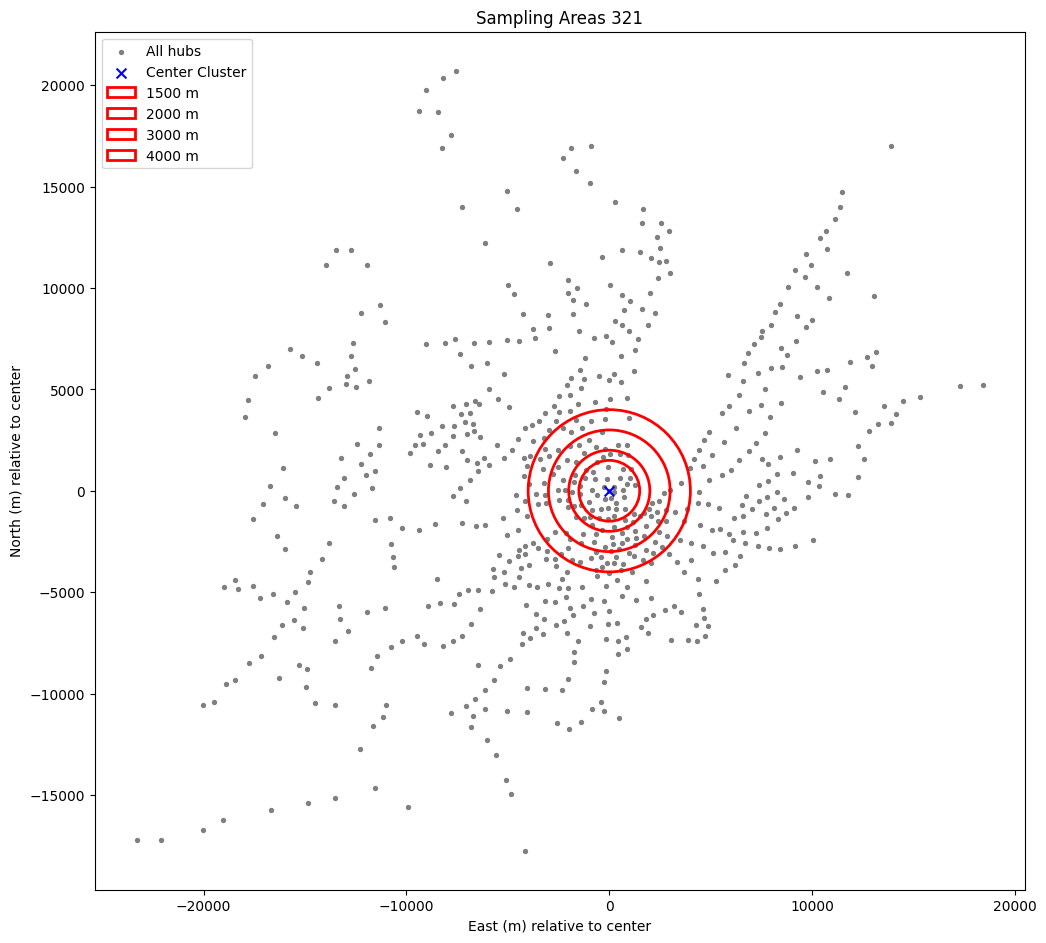

Hub 176: 34 hubs within 1500 m
Hub 176: 59 hubs within 2000 m
Hub 176: 105 hubs within 3000 m
Hub 176: 149 hubs within 4000 m


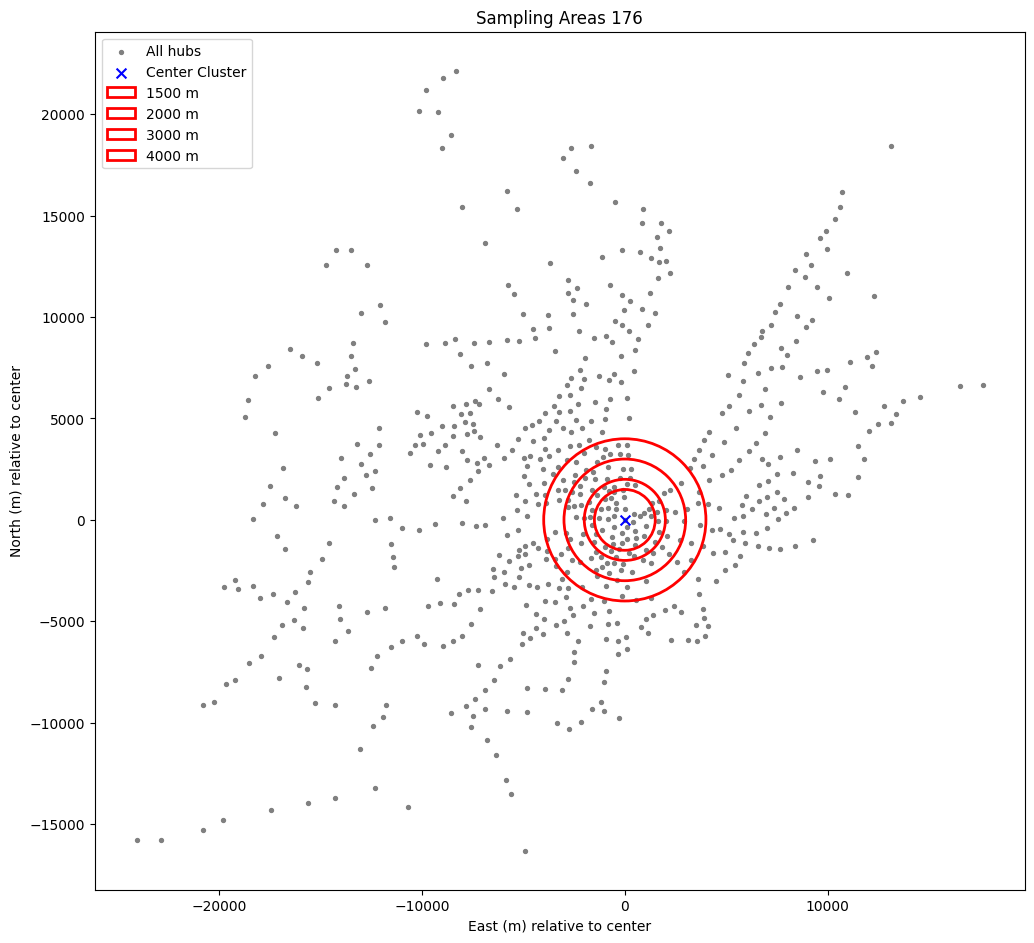

In [11]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import pandas as pd

# 1) Load hubs GeoJSON and project to metric CRS for plotting
hubs = gpd.read_file("hubs_500.geojson").to_crs(epsg=3857)

# 2) Define center hub IDs and radii
center_hub_ids = [321, 176]
radii = [1500, 2000, 3000, 4000]  # in meters

# 3) Plot for each center
for hub_id in center_hub_ids:
    center = hubs[hubs["hub_id"] == hub_id]
    if center.empty:
        print(f"Hub {hub_id} not found")
        continue

    cx, cy = center.geometry.x.iloc[0], center.geometry.y.iloc[0]

    # Compute relative coordinates
    hubs["rel_x"] = hubs.geometry.x - cx
    hubs["rel_y"] = hubs.geometry.y - cy

    fig, ax = plt.subplots(figsize=(12,12))
    # Plot all hub centroids
    ax.scatter(hubs["rel_x"], hubs["rel_y"], s=8, color="grey", label="All hubs")
    # Highlight center hub
    ax.scatter(0, 0, s=50, color="blue", marker="x", label=f"Center Cluster")

    # Draw circles and annotate
    for r in radii:
        circle = plt.Circle((0,0), r, fill=False, linewidth=2,color = 'red', label=f"{r} m")
        ax.add_patch(circle)

        # Count hubs within radius
        inside = hubs[(hubs["geometry"].distance(center.geometry.iloc[0]) <= r)]
        print(f"Hub {hub_id}: {len(inside)} hubs within {r} m")

    ax.set_aspect("equal", "box")
    ax.set_xlabel("East (m) relative to center")
    ax.set_ylabel("North (m) relative to center")
    ax.set_title(f"Sampling Areas {hub_id}")
    ax.legend()
    plt.show()


In [30]:
import os
import json
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

# 0) Prepare full stations GeoDataFrame (from your stations.json)
with open("stations.json", encoding="utf-8") as f:
    stations_doc = json.load(f)
generated_at = stations_doc["generated_at"]
stations = pd.DataFrame(stations_doc["stations"])
st_gdf = gpd.GeoDataFrame(
    stations,
    geometry=[Point(xy) for xy in zip(stations["lon"], stations["lat"])],
    crs="EPSG:4326"
)

# 1) List of hub‐radius GeoJSON files
geo_files = [
    r"C:\Users\mesut\Desktop\Yeni klasör\hub_321_6000m.geojson",
    r"C:\Users\mesut\Desktop\Yeni klasör\hub_87_2000m.geojson",
    r"C:\Users\mesut\Desktop\Yeni klasör\hub_87_4000m.geojson",
    r"C:\Users\mesut\Desktop\Yeni klasör\hub_87_6000m.geojson",
    r"C:\Users\mesut\Desktop\Yeni klasör\hub_321_2000m.geojson",
    r"C:\Users\mesut\Desktop\Yeni klasör\hub_321_4000m.geojson"
]

# 2) Loop over each GeoJSON, parse hub_id & radius, then sample stations
for path in geo_files:
    # derive stem 'hub_<hub_id>_<radius>m'
    stem = os.path.splitext(os.path.basename(path))[0]
    _, hub_id, radius_str = stem.split("_")
    radius_m = int(radius_str.rstrip("m"))

    # load and extract the buffer polygon
    inst = gpd.read_file(path)
    buffer_poly = inst.loc[inst["radius_m"] == radius_m, "geometry"].iloc[0]

    # select stations within the polygon
    sampled = st_gdf[st_gdf.within(buffer_poly)].copy()

    # build output dict
    out = {
        "generated_at": generated_at,
        "stations": sampled[["station_id","type","name","lat","lon"]]
                     .to_dict(orient="records")
    }

    # write a new stations_<stem>.json
    out_fname = f"stations_{stem}.json"
    with open(out_fname, "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False, indent=2)

    print(f"Wrote {len(out['stations'])} stations to {out_fname}")


Wrote 2775 stations to stations_hub_321_6000m.json
Wrote 845 stations to stations_hub_87_2000m.json
Wrote 1719 stations to stations_hub_87_4000m.json
Wrote 2854 stations to stations_hub_87_6000m.json
Wrote 738 stations to stations_hub_321_2000m.json
Wrote 1763 stations to stations_hub_321_4000m.json


# Create Alternatives

In [1]:
import psutil

import os

P_CORES = list(range(12))
proc = psutil.Process(os.getpid())
proc.cpu_affinity(P_CORES)

print('affinity set to:', psutil.Process().cpu_affinity())


affinity set to: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


In [2]:
import os, psutil
print(psutil.Process(os.getpid()).cpu_affinity())


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


In [ ]:


import json
import math
import itertools
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from concurrent.futures import ThreadPoolExecutor, as_completed
import geopandas as gpd
from itertools import count

# ─── Configuration ─────────────────────────────────────────────────────
GRAPHQL_URL = "http://localhost:8080/otp/transmodel/v3"
GRAPHQL_QUERY = """query trip(
    $from: Location!, $to: Location!, $dateTime: DateTime!,
    $modes: Modes!, $maximumTransfers: Int,
    $bikeSpeed: Float, $walkSpeed: Float,
    $bicycleOptimisationMethod: BicycleOptimisationMethod,
    $maxAccessEgressDurationForMode: [StreetModeDurationInput!],
    $arriveBy: Boolean, $searchWindow: Int
  ) {
  trip(
    from:$from, to:$to, dateTime:$dateTime,
    modes:$modes, maximumTransfers:$maximumTransfers,
    bikeSpeed:$bikeSpeed, walkSpeed:$walkSpeed,
    bicycleOptimisationMethod:$bicycleOptimisationMethod,
    maxAccessEgressDurationForMode:$maxAccessEgressDurationForMode,
    arriveBy:$arriveBy, searchWindow:$searchWindow
  ) {
    tripPatterns { legs {
      mode duration distance
      line { publicCode }
      toPlace { name }
    }}
  }
}"""
fixed_timestamp = "2025-07-23T10:00:00Z"
PARAMS = {
    "maximumTransfers": 3,
    "bikeSpeed": 5.0,
    "walkSpeed": 1.4,
    "bicycleOptimisationMethod": "quick",
    "maxAccessEgressDurationForMode": [{"streetMode":"bike_rental","duration":"25m"}],
    "arriveBy": True,
    "searchWindow": 120,
    "modes": {"accessMode":"bike_rental","egressMode":"bike_rental"}
}
MAX_WORKERS = 20
CACHE_FILE = "od_cache.json"
global_arc_counter = count()
# ─── HTTP session pool & retry ──────────────────────────────────────────
session = requests.Session()
adapter = HTTPAdapter(pool_connections=100, pool_maxsize=100,
                      max_retries=Retry(total=2, backoff_factor=0.1))
session.mount("http://", adapter)
session.mount("https://", adapter)

def haversine(lat1, lon1, lat2, lon2):
    R = 6371e3
    φ1, φ2 = math.radians(lat1), math.radians(lon1)
    Δφ, Δλ = math.radians(lat2-lat1), math.radians(lon2-lon1)
    a = math.sin(Δφ/2)**2 + math.cos(φ1)*math.cos(math.radians(lat2))*math.sin(Δλ/2)**2
    return 2 * R * math.atan2(math.sqrt(a), math.sqrt(1-a))

# ─── Load or init cache ─────────────────────────────────────────────────
try:
    with open(CACHE_FILE, "r", encoding="utf-8") as f:
        cache = json.load(f)
except Exception:
    cache = {}

hub_files = sorted(f for f in os.listdir(".") if f.startswith("hub_500_") and f.endswith("m.geojson"))

for hub_file in hub_files:
    print(f"\n--- Processing {hub_file} ---")

    # 1) Load raw GeoJSON
    with open(hub_file, "r", encoding="utf-8") as gf:
        gj = json.load(gf)

    # 2) Extract only Point features as hub centroids
    hub_records = []
    for feat in gj.get("features", []):
        geom = feat.get("geometry", {})
        if geom.get("type") != "Point":
            continue
        lon, lat = geom["coordinates"]
        hub_id = feat["properties"]["hub_id"]
        hub_records.append({"hub_id": hub_id, "lat": lat, "lon": lon})

    print(f"Found {len(hub_records)} hub centroids")

    # 3) Build all O→D permutations (skip < 500 m)
    pairs = [
        (o, d) for o, d in itertools.permutations(hub_records, 2)
        if haversine(o["lat"], o["lon"], d["lat"], d["lon"]) >= 500
    ]

    # 4) Split into cached vs new
    to_query, results = [], []
    for orig, dest in pairs:
        key = f"{orig['hub_id']}|{dest['hub_id']}"
        if key in cache:
            results.append(cache[key])
        else:
            to_query.append((orig, dest, key))

    print(f"{len(results)} cached, {len(to_query)} to query")

    # 5) Worker (unchanged)
    def worker(orig, dest, key):
        vars = {
            "from":     {"coordinates": {"latitude": orig["lat"],  "longitude": orig["lon"]}},
            "to":       {"coordinates": {"latitude": dest["lat"], "longitude": dest["lon"]}},
            "dateTime": fixed_timestamp,
            **PARAMS
        }
        try:
            r = session.post(GRAPHQL_URL, json={"query": GRAPHQL_QUERY, "variables": vars}, timeout=60)
            r.raise_for_status()
            patterns = r.json().get("data",{}).get("trip",{}).get("tripPatterns", [])
        except Exception as e:
            print(f"Error {key}: {e}")
            return None
        if not patterns:
            return None

        arc_pt_bike, arc_pt_only, arc_car = [], [], []
        for pat in patterns:
            arc_id = next(global_arc_counter)
            total_travel = total_transfer = total_dist = 0
            legs_info = []
            bike_indices = []
            pt_indices = []
            for li, leg in enumerate(pat["legs"]):
                mode = leg["mode"].upper()
                dur = leg["duration"]; dist_leg = leg["distance"]
                if mode == "FOOT":
                    total_transfer += dur
                else:
                    total_travel += dur
                total_dist += dist_leg
                if "BICYCLE" in mode: bike_indices.append(li)
                if mode in ("BUS","TRAM"): pt_indices.append(li)
                legs_info.append({
                    "leg_idx": li,
                    "mode": mode,
                    "duration_s": dur,
                    "distance_m": dist_leg,
                    "line_publicCode": leg.get("line", {}),
                    "to_place": leg["toPlace"]["name"]
                })
            if bike_indices and pt_indices:
                access_bike = min(bike_indices) < min(pt_indices)
                egress_bike = max(bike_indices) > max(pt_indices)
            else:
                access_bike = bool(bike_indices)
                egress_bike = bool(bike_indices)
            arc_entry = {
                "arc_id": arc_id,
                "access_bike": access_bike,
                "egress_bike": egress_bike,
                "total_travel_time_s": total_travel,
                "total_transfer_time_s": total_transfer,
                "total_distance_m": total_dist,
                "legs": legs_info
            }
            if bike_indices and pt_indices:
                arc_pt_bike.append(arc_entry)
            elif pt_indices:
                arc_pt_only.append(arc_entry)
            else:
                arc_car.append(arc_entry)

        result = {
            "from_id":    orig["hub_id"],
            "to_id":      dest["hub_id"],
            "arc_pt_bike": arc_pt_bike,
            "arc_pt_only": arc_pt_only,
            "arc_car":     arc_car
        }
        cache[key] = result
        return result

    # 6) Run the queries in parallel
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as exe:
        futures = {exe.submit(worker,o,d,key):(o,d) for o,d,key in to_query}
        for fut in as_completed(futures):
            res = fut.result()
            if res:
                results.append(res)

    # 7) Save and update cache (unchanged)
    stem = os.path.splitext(hub_file)[0]
    out_name = f"od_results_{stem}.json"
    with open(out_name, "w", encoding="utf-8") as wf:
        json.dump({"generated_at": fixed_timestamp, "od_results": results},
                  wf, ensure_ascii=False, indent=2)
    print(f"Wrote {len(results)} O–D entries to {out_name}")

    with open(CACHE_FILE, "w", encoding="utf-8") as cf:
        json.dump(cache, cf, ensure_ascii=False, indent=2)
    print(f"Cache now has {len(cache)} entries")



--- Processing hub_321_1500m.geojson ---
Found 54 hub centroids
1669 cached, 643 to query
Wrote 1669 O–D entries to od_results_hub_321_1500m.json
Cache now has 40548 entries

--- Processing hub_321_3000m.geojson ---
Found 145 hub centroids
17828 cached, 1696 to query
Wrote 17828 O–D entries to od_results_hub_321_3000m.json
Cache now has 40548 entries

--- Processing hub_87_1500m.geojson ---
Found 54 hub centroids
1810 cached, 516 to query
Wrote 1810 O–D entries to od_results_hub_87_1500m.json
Cache now has 40548 entries

--- Processing hub_87_2000m.geojson ---
Found 89 hub centroids
5870 cached, 1038 to query
Wrote 5870 O–D entries to od_results_hub_87_2000m.json
Cache now has 40548 entries

--- Processing hub_87_3000m.geojson ---
Found 153 hub centroids
18442 cached, 3338 to query
Wrote 19861 O–D entries to od_results_hub_87_3000m.json
Cache now has 41967 entries

--- Processing hub_87_4000m.geojson ---
Found 207 hub centroids
29464 cached, 11418 to query
Wrote 38506 O–D entries to o

## Sanity check code

In [ ]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import json

# ─── 1) Reuse your HTTP session for pooling & retries ──────────────
session = requests.Session()
adapter = HTTPAdapter(pool_connections=10, pool_maxsize=10,
                      max_retries=Retry(total=2, backoff_factor=0.1))
session.mount("http://", adapter)
session.mount("https://", adapter)

# ─── 2) GraphQL endpoint & query ─────────────────────────────────
GRAPHQL_URL = "http://localhost:8080/otp/transmodel/v3"
GRAPHQL_QUERY = """
query simpleTrip($from: Location!, $to: Location!) {
  trip(from: $from, to: $to) {
    tripPatterns {
      duration
      distance
      legs {
        mode
        line { publicCode }
        toPlace { name }
      }
    }
  }
}
"""

# ─── 3) Hard‑coded coordinates for sanity check ────────────────────
origin      = {"coordinates": {"latitude": 46.209439733014939, "longitude": 6.146652614285714}}
destination = {"coordinates": {"latitude": 46.197245483955307, "longitude": 6.15333588}}

payload = {
  "query": GRAPHQL_QUERY,
  "variables": {
    "from": origin,
    "to": destination,
    "modes": {
    "direct":     "car_pickup",
    "directOnly": True

  }
  }
}

# ─── 4) Execute and inspect ───────────────────────────────────────
resp = session.post(GRAPHQL_URL, json=payload, timeout=10)
resp.raise_for_status()
data = resp.json()

print("Full response:")
print(json.dumps(data, indent=2))

patterns = data.get("data", {}).get("trip", {}).get("tripPatterns", [])
if not patterns:
    print("❌ No tripPatterns returned.")
else:
    first = patterns[0]
    print("\n✅ First trip pattern:")
    print(f"  • Duration: {first['duration']} seconds")
    print(f"  • Distance: {first['distance']} meters")
    print("  • Legs:")
    for leg in first["legs"]:
        print(f"    – {leg['mode']} → {leg.get('line',{})} → {leg['toPlace']['name']}")


# Combining Files

In [3]:
import json
import os

# 1) Explicitly list your files (replace with your actual paths)
file_paths = [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\od_results.json"
]

# 2) Process each path
for path in file_paths:
    print(f"Updating {path}…")
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # 3) Rewrite arc_id in each OD entry
    for od in data.get("od_results", []):
        for arc in od.get("arc_pt_bike", []):
            arc["arc_id"] = f"a_mm_{arc['arc_id']}"
        for arc in od.get("arc_pt_only", []):
            arc["arc_id"] = f"a_pt_{arc['arc_id']}"
        # if you also need to prefix car arcs, uncomment:
        for arc in od.get("arc_car", []):
             arc["arc_id"] = f"c_{arc['arc_id']}"

    # 4) Write back
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)

    print(f"→ Done. Saved {os.path.basename(path)}")


Updating C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\od_results.json…


AttributeError: 'list' object has no attribute 'get'

In [ ]:
import json
import os

# 1) List of your car‑only result files
file_paths = [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\bike_paths\od_results_hub_87_1500m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\bike_paths\od_results_hub_87_2000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\bike_paths\od_results_hub_87_3000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\bike_paths\od_results_hub_87_4000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\bike_paths\od_results_hub_321_1500m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\bike_paths\od_results_hub_321_2000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\bike_paths\od_results_hub_321_3000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\bike_paths\od_results_hub_321_4000m.json"]

# 2) Process each file
for path in file_paths:
    print(f"Updating {path}…")
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # 3) Prefix every car arc_id with 'b_'
    for od in data.get("od_results", []):
        for arc in od.get("arc_car", []):
            arc["arc_id"] = f"a_bike_{arc['arc_id']}"

    # 4) Write the file back
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)

    print(f"→ Done. Saved {os.path.basename(path)}")


Updating C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\car_paths\cache\od_cache.json…
→ Done. Saved od_cache.json


In [1]:
import json
import os

# 1) Your file lists (replace with real paths)
pt_files = [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_87_2000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_87_3000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_87_4000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_321_1500m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_321_2000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_321_3000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_321_4000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_87_1500m.json"
    # …
]
car_cache_files = [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\car_paths\cache\od_cache.json"
]

# 2) Load all car caches into one dict
car_cache = {}
for cfile in car_cache_files:
    with open(cfile, "r", encoding="utf-8") as f:
        car_cache.update(json.load(f))   # expects {"0|149": {…}, …}

# 3) For each PT file, merge in car arcs
for pt_path in pt_files:
    print(f"\nMerging car arcs into {pt_path}…")
    with open(pt_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    missing = []
    for od in data.get("od_results", []):
        key = f"{od['from_id']}|{od['to_id']}"
        car_entry = car_cache.get(key)
        if car_entry and car_entry.get("arc_car"):
            # overwrite the existing empty arc_car with the cached one
            od["arc_car"] = car_entry["arc_car"]
        else:
            # no car arcs found for this O→D
            missing.append(key)
            # ensure the field exists
            od["arc_car"] = []

    # 4) Write merged file back
    with open(pt_path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)
    print(f"→ Done. {len(missing)} O→D pairs had no car paths:")
    print(", ".join(missing))



Merging car arcs into C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_87_2000m.json…
→ Done. 0 O→D pairs had no car paths:


Merging car arcs into C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_87_3000m.json…
→ Done. 0 O→D pairs had no car paths:


Merging car arcs into C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_87_4000m.json…
→ Done. 0 O→D pairs had no car paths:


Merging car arcs into C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_321_1500m.json…
→ Done. 0 O→D pairs had no car paths:


Merging car arcs into C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_321_2000m.json…
→ Done. 0 O→D pairs had no car paths:


Merging car arcs into C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\merged\od_results_hub_321_3000m.json…
→ Done. 0 O→D pairs had no car paths:


Merging car arcs into C:\Users\mkoseogl\Desktop\

In [3]:
import json
import os
import random


def generate_instance(
    merged_arcs_path: str,
    stations_path: str,
    save_folder: str,
    fixed_capacity: int,
    min_demand: int,
    max_demand: int,
    min_inventory_pct: float,
    max_inventory_pct: float,
    min_park_time: float,
    max_park_time: float,
    seed: int = None
) -> str:
    """
    Generate a JSON instance for the bike-PT integration problem, inheriting timestamp from merged data.

    Converts distances to kilometers and durations to minutes.
    Adds 'total_travel_cost' and 'parking_time_min' to each car arc, computed as:
      fuel_cost = total_distance_km * (FUEL_PRICE_CHF_PER_L * EFFICIENCY_L_PER_100KM / 100)
      parking_time_min ~ Uniform(min_park_time, max_park_time)
      total_travel_time_min += parking_time_min
      + DEPRECIATION_COST added to cost

    Parameters:
        merged_arcs_path: Path to the merged arcs JSON file containing od_results and a generated_at field.
        stations_path: Path to the stations JSON file containing station definitions.
        save_folder: Directory where the generated instance JSON will be saved.
        fixed_capacity: Capacity to assign to every bike station.
        min_demand, max_demand: Inclusive range for random OD demand values.
        min_inventory_pct, max_inventory_pct: Fractional bounds (0-1) for inventory relative to capacity.
        min_park_time, max_park_time: Bounds for random parking search time (minutes) for car arcs.
        seed: Optional random seed for reproducibility.

    Returns:
        A tuple of (instance_name, file path of the saved instance).
    """
    # Constants for car cost calculation
    FUEL_PRICE_CHF_PER_L   = 2.0
    EFFICIENCY_L_PER_100KM = 8.0
    DEPRECIATION_COST      = 3.27
    FUEL_CHF_PER_KM        = FUEL_PRICE_CHF_PER_L * EFFICIENCY_L_PER_100KM / 100.0

    if seed is not None:
        random.seed(seed)

    # Load merged data
    with open(merged_arcs_path, 'r', encoding='utf-8') as f:
        merged = json.load(f)
    gen_time = merged.get('generated_at')

    # Load station definitions
    with open(stations_path, 'r', encoding='utf-8') as f:
        stations_data = json.load(f)

    # Map bike-sharing station names to IDs
    bike_stations = [s for s in stations_data.get('stations', []) if s.get('type') == 'bs']
    name_to_id    = {s['name'].strip(): s['station_id'] for s in bike_stations}
    station_ids   = list(name_to_id.values())

    # Station capacities and random inventories
    station_capacity  = {sid: fixed_capacity for sid in station_ids}
    station_inventory = {}
    for sid, cap in station_capacity.items():
        low  = min(int(cap * min_inventory_pct), cap)
        high = min(int(cap * max_inventory_pct), cap)
        station_inventory[sid] = random.randint(low, high)

    bike_station_info = {
        'station_list':     station_ids,
        'station_capacity': station_capacity,
        'station_inventory':station_inventory
    }

    # Prepare OD pairs and group arcs by OD
    OD_pairs    = []
    arcs_pt_bike= {}
    arcs_pt_only= {}
    car_paths   = {}
    origins     = set()
    destinations= set()
    total_demand= 0

    for od in merged.get('od_results', []):
        o, d = od.get('from_id'), od.get('to_id')
        key  = f"{o}_{d}"

        demand = random.randint(min_demand, max_demand)
        OD_pairs.append({'origin': o, 'destination': d, 'demand': demand})
        origins.add(o); destinations.add(d); total_demand += demand

        # PT+Bike arcs conversion
        ptb = od.get('arc_pt_bike', [])
        for arc in ptb:
            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
            for leg in arc.get('legs', []):
                leg['duration_min']         = leg.get('duration_s', 0) / 60.0
                leg['distance_km']          = leg.get('distance_m', 0.0) / 1000.0
        arcs_pt_bike[key] = ptb

        # PT-only arcs conversion
        pto = od.get('arc_pt_only', [])
        for arc in pto:
            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
        arcs_pt_only[key] = pto

        # Car arcs conversion, cost, and parking time
        car = od.get('arc_car', [])
        for arc in car:
            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
            # random parking search time
            parking_time = random.uniform(min_park_time, max_park_time)
            arc['parking_time_min']       = parking_time
            arc['total_travel_and_parking_time_min'] = parking_time + arc['total_travel_time_min']
            # compute cost
            dist_km      = arc['total_distance_km']
            fuel_cost    = dist_km * FUEL_CHF_PER_KM
            arc['total_travel_cost']     = fuel_cost + DEPRECIATION_COST
        car_paths[key] = car

    # Summary info
    info = {
        'num_OD_pairs':           len(OD_pairs),
        'num_bike_stations':      len(station_ids),
        'num_unique_origins':     len(origins),
        'num_unique_destinations':len(destinations),
        'total_demand':           total_demand
    }

    instance_name = f"Instance_{info['num_OD_pairs']}"
    filename      = f"{instance_name}.json"

    # Compute flat delta_ia per PT+bike arc
    delta_ia = {}
    for arc_list in arcs_pt_bike.values():
        for arc in arc_list:
            aid = arc.get('arc_id')
            for i, leg in enumerate(arc.get('legs', [])):
                if leg.get('mode') == 'BICYCLE':
                    sid_in  = name_to_id.get(leg.get('to_place','').strip())
                    prev    = arc['legs'][i-1].get('to_place','').strip() if i>0 else None
                    sid_out = name_to_id.get(prev) if prev else None
                    delta   = {}
                    if sid_out is not None: delta[sid_out] = -1
                    if sid_in  is not None: delta[sid_in]  = 1
                    delta_ia[aid] = delta
                    break

    instance = {
        'generated_at': gen_time,
        'random_seed':  seed,
        'info':         info,
        'bike_stations':bike_station_info,
        'OD_pairs':     OD_pairs,
        'arcs_pt_bike': arcs_pt_bike,
        'arcs_pt_only': arcs_pt_only,
        'car_paths':    car_paths,
        'delta_ia':     delta_ia
    }

    os.makedirs(save_folder, exist_ok=True)
    out_path = os.path.join(save_folder, filename)
    with open(out_path, 'w', encoding='utf-8') as f:
        json.dump(instance, f, indent=2, ensure_ascii=False)

    return instance_name, out_path




In [ ]:
import json
import os
import random
import math

def haversine(coord1, coord2):
    """
    Returns great‐circle distance (km) between two (lat, lon) pairs.
    """
    R = 6371.0  # Earth radius in km
    lat1, lon1 = math.radians(coord1[0]), math.radians(coord1[1])
    lat2, lon2 = math.radians(coord2[0]), math.radians(coord2[1])
    dlat, dlon = lat2 - lat1, lon2 - lon1

    a = math.sin(dlat/2)**2 + math.cos(lat1)*math.cos(lat2)*math.sin(dlon/2)**2
    return R * 2 * math.asin(math.sqrt(a))

def _recover_backward(legs, idx, name_to_id):
    for j in range(idx, -1, -1):
        p = legs[j].get('to_place','').strip()
        if p in name_to_id and p.lower() != 'bike':
            return p
    return None



def generate_instance(
    merged_arcs_path: str,
    stations_path: str,
    hubs_geojson_path: str,
    save_folder: str,
    fixed_capacity: int,
    min_demand: int,
    max_demand: int,
    min_inventory_pct: float,
    max_inventory_pct: float,
    min_park_time: float,
    max_park_time: float,
    seed: int = None
) -> str:
    """
    Generate a JSON instance for the bike-PT integration problem, inheriting timestamp from merged data.

    Converts distances to kilometers and durations to minutes.
    Adds 'total_travel_cost' and 'parking_time_min' to each car arc, computed as:
      fuel_cost = total_distance_km * (FUEL_PRICE_CHF_PER_L * EFFICIENCY_L_PER_100KM / 100)
      parking_time_min ~ Uniform(min_park_time, max_park_time)
      total_travel_time_min += parking_time_min
      + DEPRECIATION_COST added to cost

    Parameters:
        merged_arcs_path: Path to the merged arcs JSON file containing od_results and a generated_at field.
        stations_path: Path to the stations JSON file containing station definitions.
        save_folder: Directory where the generated instance JSON will be saved.
        fixed_capacity: Capacity to assign to every bike station.
        min_demand, max_demand: Inclusive range for random OD demand values.
        min_inventory_pct, max_inventory_pct: Fractional bounds (0-1) for inventory relative to capacity.
        min_park_time, max_park_time: Bounds for random parking search time (minutes) for car arcs.
        seed: Optional random seed for reproducibility.

    Returns:
        A tuple of (instance_name, file path of the saved instance).
    """
    # Constants for car cost calculation
    FUEL_PRICE_CHF_PER_L   = 2.0
    EFFICIENCY_L_PER_100KM = 8.0
    DEPRECIATION_COST      = 3.27
    FUEL_CHF_PER_KM        = FUEL_PRICE_CHF_PER_L * EFFICIENCY_L_PER_100KM / 100.0

    if seed is not None:
        random.seed(seed)

    # Load merged data
    with open(merged_arcs_path, 'r', encoding='utf-8') as f:
        merged = json.load(f)
    gen_time = merged.get('generated_at')

    # Load station definitions
    with open(stations_path, 'r', encoding='utf-8') as f:
        stations_data = json.load(f)

    # Map bike-sharing station names to IDs
    bike_stations = [s for s in stations_data.get('stations', []) if s.get('type') == 'bs']
    name_to_id    = {s['name'].strip(): s['station_id'] for s in bike_stations}
    id_to_name = { sid: name for name, sid in name_to_id.items() }
    station_coords= {s['station_id']:(s['lat'],s['lon']) for s in bike_stations}
    station_ids   = list(name_to_id.values())
    
    # load hubs.geojson for centroids
    with open(hubs_geojson_path, 'r', encoding='utf-8') as f:
        hubs_gj = json.load(f)
    hub_coords = {
        feat['properties']['hub_id']: tuple(feat['geometry']['coordinates'][::-1])  
        for feat in hubs_gj['features']
    }
    hub_to_bss = {
    feat['properties']['hub_id']: feat['properties']['bike_stations']
    for feat in hubs_gj['features']
    }
    pt_stations = [s for s in stations_data['stations'] if s['type']=='pt']
    pt_name_to_id = { s['name'].strip(): s['station_id'] for s in pt_stations }
    pt_coords_by_id = { s['station_id']: (s['lat'], s['lon']) for s in pt_stations }

    pt_to_hub = {}
    for feat in hubs_gj['features']:
        hid = feat['properties']['hub_id']
        for pts in feat['properties']['pt_stations']:
            pt_to_hub[pts.strip()] = hid

    # Station capacities and random inventories
    station_capacity  = {sid: fixed_capacity for sid in station_ids}
    station_inventory = {}
    for sid, cap in station_capacity.items():
        low  = min(int(cap * min_inventory_pct), cap)
        high = min(int(cap * max_inventory_pct), cap)
        station_inventory[sid] = random.randint(low, high)

    bike_station_info = {
        'station_list':     station_ids,
        'station_capacity': station_capacity,
        'station_inventory':station_inventory
    }

    # Prepare OD pairs and group arcs by OD
    OD_pairs    = []
    arcs_pt_bike= {}
    arcs_pt_only= {}
    car_paths   = {}
    origins     = set()
    destinations= set()
    total_demand= 0

    for od in merged.get('od_results', []):
        o, d = od.get('from_id'), od.get('to_id')
        key  = f"{o}_{d}"

        demand = random.randint(min_demand, max_demand)
        OD_pairs.append({'origin': o, 'destination': d, 'demand': demand})
        origins.add(o); destinations.add(d); total_demand += demand

        # PT+Bike arcs conversion
        ptb = od.get('arc_pt_bike', [])
        for arc in ptb:
            legs = arc['legs']
            for i, leg in enumerate(legs):
                if leg['mode'] != 'BICYCLE':
                    continue

                # Try Case 1 & its backward‐fallback
                prev = legs[i-1]['to_place'].strip() if i>0 else None
                if prev and prev in name_to_id and prev.lower()!='bike':
                    leg['from_place'] = prev
                else:
                    found = _recover_backward(legs, i-1, name_to_id)
                    if found:
                        leg['from_place'] = found
                            # NEW: Case 1b: previous == "Bike" → step back one more to PT stop
                    elif i>0 and prev.lower()=='bike':
                        # find the first non‑"Bike" before that
                        pt_leg = None
                        for j in range(i-2, -1, -1):
                            cand = legs[j]['to_place'].strip()
                            if cand.lower() != 'bike':
                                pt_leg = legs[j]
                                break

                        if pt_leg:
                            pt_name   = pt_leg['to_place'].strip()
                            walk_dist = legs[i-1].get('distance_km', 0.0)                # your foot‐to‐bike walking distance
                            pt_coord  = pt_coords_by_id.get(pt_name, None)

                            if pt_coord is not None:
                                # restrict to BS in this origin‐hub
                                hubid      = o
                                candidates = hub_to_bss.get(hubid, station_coords.keys())
                                # pick the station whose haversine(pt_coord,bs_coord) ≃ walk_dist
                                best_sid = min(
                                    candidates,
                                    key=lambda sid: abs(haversine(pt_coord, station_coords[sid]) - walk_dist)
                                )
                                leg['from_place'] = id_to_name[best_sid]
                    else:
                        # Case 2: first leg bicycle
                        if i == 0:
                            ox, oy = hub_coords[o]
                            # nearest station to origin
                            candidates = hub_to_bss[o]                                  # ⬅️ MOD
                            best_sid = min(                                             # ⬅️ CHG
                                ((sid, station_coords[sid]) for sid in candidates),    # ⬅️ CHG
                                key=lambda kv: haversine((oy,ox), kv[1])
                            )[0]
                            leg['from_place'] = id_to_name[best_sid]

                        # Case 4: second leg & first was “Bike”
                        elif i == 1 and legs[0]['to_place'].strip().lower()=='bike':
                            walk_dist = legs[0].get('distance_km',0.0)
                            ox, oy = hub_coords[o]
                            candidates = hub_to_bss[o]                                  # ⬅️ MOD
                            # choose station whose distance ≃ walk_dist ⬅️ CHG
                            sorted_bss = sorted(                                       # ⬅️ CHG
                                ((sid, station_coords[sid]) for sid in candidates),    # ⬅️ CHG
                                key=lambda kv: abs(haversine((oy,ox), kv[1]) - walk_dist)
                            )
                            # avoid from_place == to_place
                            for sid, _ in sorted_bss:                                  # ⬅️ MOD
                                name = id_to_name[sid]
                                if name != leg.get('to_place',''):
                                    leg['from_place'] = name
                                    

                        # Case 3 & final fallback: last leg or forward fails
                        else:
                            # snap to nearest station to *destination* hub
                            dx, dy = hub_coords[d]
                            candidates = hub_to_bss[d]                                  # ⬅️ MOD
                            sorted_bss = sorted(                                       # ⬅️ CHG
                                ((sid, station_coords[sid]) for sid in candidates),    # ⬅️ CHG
                                key=lambda kv: haversine((dy,dx), kv[1])
                            )
                            # avoid identical from/to
                            for sid, _ in sorted_bss:                                  # ⬅️ MOD
                                name = id_to_name[sid]
                                if name != leg.get('from_place',''):
                                    leg['from_place'] = name
                                    
                raw_to = leg.get('to_place','').strip()

                # 1) Handle pure “Destination” / fallback to BS
                if raw_to.lower() == 'destination' or raw_to not in name_to_id and raw_to.lower()=='destination':
                    dx, dy   = hub_coords[d]
                    candidates = hub_to_bss[d]
                    sorted_bss = sorted(
                        ((sid, station_coords[sid]) for sid in candidates),
                        key=lambda kv: haversine((dy,dx), kv[1])
                    )
                    for sid, _ in sorted_bss:
                        name = id_to_name[sid]
                        if name != leg.get('from_place',''):
                            leg['to_place'] = name
                            break

                elif raw_to not in name_to_id:
                    # map the name to its station_id
                    pt_id = pt_name_to_id.get(raw_to)
                    if pt_id and pt_id in pt_to_hub:
                        hub_id = pt_to_hub[pt_id]
                    else:
                        # fallback: assume the arc’s destination hub
                        hub_id = d

                    # get the PT‐stop coords (or fallback to hub centroid)
                    pt_coord = pt_coords_by_id.get(pt_id)
                    if pt_coord is None:
                        pt_coord = hub_coords.get(hub_id, hub_coords[o])

                    candidates = hub_to_bss.get(hub_id, station_coords.keys())
                    # sort by distance from that PT stop (or hub) → BS
                    sorted_bss = sorted(
                        ((sid, station_coords[sid]) for sid in candidates),
                        key=lambda kv: haversine(pt_coord, kv[1])
                    )
                    # pick the nearest BS that isn’t the same as from_place
                    for sid, _ in sorted_bss:
                        name = id_to_name[sid]
                        if name != leg.get('from_place',''):
                            leg['to_place'] = name
                            break

                # else: raw_to is already a valid BS name, so do nothing


            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
            for leg in arc.get('legs', []):
                leg['duration_min']         = leg.get('duration_s', 0) / 60.0
                leg['distance_km']          = leg.get('distance_m', 0.0) / 1000.0
        arcs_pt_bike[key] = ptb

        # PT-only arcs conversion
        pto = od.get('arc_pt_only', [])
        for arc in pto:
            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
        arcs_pt_only[key] = pto

        # Car arcs conversion, cost, and parking time
        car = od.get('arc_car', [])
        for arc in car:
            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
            # random parking search time
            parking_time = random.uniform(min_park_time, max_park_time)
            arc['parking_time_min']       = parking_time
            arc['total_travel_and_parking_time_min'] = parking_time + arc['total_travel_time_min']
            # compute cost
            dist_km      = arc['total_distance_km']
            fuel_cost    = dist_km * FUEL_CHF_PER_KM
            arc['total_travel_cost']     = fuel_cost + DEPRECIATION_COST
        car_paths[key] = car

    # Summary info
    info = {
        'num_OD_pairs':           len(OD_pairs),
        'num_bike_stations':      len(station_ids),
        'num_unique_origins':     len(origins),
        'num_unique_destinations':len(destinations),
        'total_demand':           total_demand
    }

    instance_name = f"Instance_{info['num_OD_pairs']}"
    filename      = f"{instance_name}.json"

    # Compute flat delta_ia per PT+bike arc, handling multiple bicycle legs
    delta_ia = {}

    for arc_list in arcs_pt_bike.values():
        for arc in arc_list:
            aid   = arc['arc_id']
            delta = {}      # will accumulate all bike‐leg deltas
            legs  = arc.get('legs', [])

            for i, leg in enumerate(legs):
                if leg.get('mode') != 'BICYCLE':
                    continue

                # both should now be valid station *names*
                from_name = leg.get('from_place',    '').strip()
                to_name   = leg.get('to_place',      '').strip()

                sid_out = name_to_id.get(from_name)
                sid_in  = name_to_id.get(to_name)

                if sid_out is not None:
                    delta[sid_out] = delta.get(sid_out, 0) - 1
                if sid_in is not None:
                    delta[sid_in]  = delta.get(sid_in,  0) + 1

            # if we found *any* bicycle legs, store the aggregated delta
            if delta:
                delta_ia[aid] = delta
            else:
                # no bicycle legs at all? you can skip or set delta_ia[aid] = {}
                # but better to omit so arcs without bikes simply have no entry
                pass

    instance = {
        'generated_at': gen_time,
        'random_seed':  seed,
        'info':         info,
        'bike_stations':bike_station_info,
        'OD_pairs':     OD_pairs,
        'arcs_pt_bike': arcs_pt_bike,
        'arcs_pt_only': arcs_pt_only,
        'car_paths':    car_paths,
        'delta_ia':     delta_ia
    }

    os.makedirs(save_folder, exist_ok=True)
    out_path = os.path.join(save_folder, filename)
    with open(out_path, 'w', encoding='utf-8') as f:
        json.dump(instance, f, indent=2, ensure_ascii=False)

    return instance_name, out_path




# Instance Generator

In [19]:
import json
import os
import random
import math

def haversine(coord1, coord2):
    """
    Returns great‐circle distance (km) between two (lat, lon) pairs.
    """
    R = 6371.0  # Earth radius in km
    lat1, lon1 = math.radians(coord1[0]), math.radians(coord1[1])
    lat2, lon2 = math.radians(coord2[0]), math.radians(coord2[1])
    dlat, dlon = lat2 - lat1, lon2 - lon1

    a = math.sin(dlat/2)**2 + math.cos(lat1)*math.cos(lat2)*math.sin(dlon/2)**2
    return R * 2 * math.asin(math.sqrt(a))






def generate_instance(
    merged_arcs_path: str,
    stations_path: str,
    hubs_geojson_path: str,
    save_folder: str,
    fixed_capacity: int,
    min_demand: int,
    max_demand: int,
    min_inventory_pct: float,
    max_inventory_pct: float,
    min_park_time: float,
    max_park_time: float,
    seed: int = None
) -> str:
    """
    Generate a JSON instance for the bike-PT integration problem, inheriting timestamp from merged data.

    Converts distances to kilometers and durations to minutes.
    Adds 'total_travel_cost' and 'parking_time_min' to each car arc, computed as:
      fuel_cost = total_distance_km * (FUEL_PRICE_CHF_PER_L * EFFICIENCY_L_PER_100KM / 100)
      parking_time_min ~ Uniform(min_park_time, max_park_time)
      total_travel_time_min += parking_time_min
      + DEPRECIATION_COST added to cost

    Parameters:
        merged_arcs_path: Path to the merged arcs JSON file containing od_results and a generated_at field.
        stations_path: Path to the stations JSON file containing station definitions.
        save_folder: Directory where the generated instance JSON will be saved.
        fixed_capacity: Capacity to assign to every bike station.
        min_demand, max_demand: Inclusive range for random OD demand values.
        min_inventory_pct, max_inventory_pct: Fractional bounds (0-1) for inventory relative to capacity.
        min_park_time, max_park_time: Bounds for random parking search time (minutes) for car arcs.
        seed: Optional random seed for reproducibility.

    Returns:
        A tuple of (instance_name, file path of the saved instance).
    """
    # Constants for car cost calculation
    FUEL_PRICE_CHF_PER_L   = 2.0
    EFFICIENCY_L_PER_100KM = 8.0
    DEPRECIATION_COST      = 3.27
    FUEL_CHF_PER_KM        = FUEL_PRICE_CHF_PER_L * EFFICIENCY_L_PER_100KM / 100.0

    if seed is not None:
        random.seed(seed)

    # Load merged data
    with open(merged_arcs_path, 'r', encoding='utf-8') as f:
        merged = json.load(f)
    gen_time = merged.get('generated_at')

    # Load station definitions
    with open(stations_path, 'r', encoding='utf-8') as f:
        stations_data = json.load(f)

    # Map bike-sharing station names to IDs
    bike_stations = [s for s in stations_data.get('stations', []) if s.get('type') == 'bs']
    name_to_id    = {s['name'].strip().lower(): s['station_id'] for s in bike_stations}
    id_to_name = { sid: name for name, sid in name_to_id.items() }
    station_coords= {s['station_id']:(s['lat'],s['lon']) for s in bike_stations}
    station_ids   = list(name_to_id.values())

    def is_bs(name: str) -> bool:
        """True iff *name* is a bike‑sharing station, case‑insensitive."""
        return name.strip().lower() in name_to_id

    def _infer_from_station(legs: list[dict], i: int, od_origin: int) -> str | None:
        """
        Return a *bike station name* to use as from_place for the bicycle leg at index *i*,
        or None if we cannot deduce one.
        """
        # ---------- Simple case: previous leg goes to a bike station ----------
        if i > 0 and is_bs(legs[i-1]['to_place']):
            return legs[i-1]['to_place'].strip()

        # ---------- Harder case: previous is FOOT to 'Bike' / 'Ebike' ----------
        if (
            i > 1
            and legs[i-1]["mode"] == "FOOT"
            and legs[i-1]["to_place"].strip().lower() in {"bike", "ebike"}
        ):
            back = legs[i-2]["to_place"].strip()

            # 1a) earlier place is already a bike station
            if is_bs(back):
                return back

            # 1b) earlier place is a PT stop → match walking distance
            if back in pt_name_to_id:
                pt_id  = pt_name_to_id[back]
                pt_xy  = pt_coords_by_id.get(pt_id)
                if pt_xy is None:            # corrupted input, bail out
                    return None

                walk_d = legs[i-1]["distance_m"] / 1000.0  # km

                # ── NEW: search over *all* bike stations, not just the hub ──
                pool = station_coords.keys()               # never empty

                best = min(
                    pool,
                    key=lambda sid: abs(haversine(pt_xy, station_coords[sid]) - walk_d)
                )
                return id_to_name[best]

        # ---------- First leg is bicycle ----------
        if i == 0:
            hub_xy = hub_coords[od_origin]            # you must pass od_origin in the call
            best   = min(hub_to_bss[od_origin],
                        key=lambda sid: haversine(hub_xy, station_coords[sid]))
            return id_to_name[best]


        # ---------- Second leg and first was 'Bike' ----------
        if (
            i == 1
            and legs[0]["mode"] == "FOOT"
            and legs[0]["to_place"].strip().lower() in {"bike", "ebike"}
        ):
            walk_d  = legs[0]["distance_m"] / 1000.0      # km
            hub_xy  = hub_coords[od_origin]
            pool    = hub_to_bss.get(od_origin) or station_coords.keys()
            best    = min(
                pool,
                key=lambda sid: abs(haversine(hub_xy, station_coords[sid]) - walk_d)
            )
            return id_to_name[best]
        
        # ---------- We have no clue ----------
        return None
    def canon(name: str | None) -> str | None:
        if name is None:
            return None
        sid = name_to_id.get(name.strip().lower())
        return id_to_name[sid] if sid else name

    def _fix_to_station(leg: dict, od_dest: int, arc_id: str) -> None:
        """
        Mutates *leg* in place if its to_place is not a bike station,
        following the rules you specified.
        """
        raw_to = leg['to_place'].strip()
        if is_bs(raw_to):                # already fine
            return

        # ---------- Last leg: 'Destination' ----------
        if raw_to.lower() == 'destination':
            hub_xy = hub_coords[od_dest]                 # pass od_dest from the caller
            pool   = hub_to_bss.get(od_dest, [])

            #if not pool:                                   # DEBUG ─ only empty cases
                #print(f"[DBG] hub_id {od_dest} has no bike stations")
            best   = min(hub_to_bss[od_dest],
                        key=lambda sid: haversine(hub_xy, station_coords[sid]))
            leg['to_place'] = id_to_name[best]
            return

        # ---------- PT stop ----------
        if raw_to in pt_name_to_id:
            pt_id = pt_name_to_id[raw_to]
            pt_xy = pt_coords_by_id[pt_id]
            hub   = pt_to_hub.get(pt_id, od_dest)
            pool  = hub_to_bss.get(hub, station_coords.keys())
            if not pool:                     # DEBUG line you asked for
                #print(f"[DBG] arc_id={arc_id}  PT_stop='{raw_to}'  hub={hub} has no bike stations")
                return False                 
            best  = min(pool, key=lambda sid: haversine(pt_xy, station_coords[sid]))
            leg['to_place'] = id_to_name[best]
            return True

    # load hubs.geojson for centroids
    with open(hubs_geojson_path, 'r', encoding='utf-8') as f:
        hubs_gj = json.load(f)

    hub_is_pt_bike = {
        feat["properties"]["hub_id"]:
            feat["properties"].get("label", "").lower() == "pt+bike station"
        for feat in hubs_gj["features"]
    }
    
    hub_coords = {
        feat['properties']['hub_id']: tuple(feat['geometry']['coordinates'][::-1])  
        for feat in hubs_gj['features']
    }
    hub_to_bss = {
    feat['properties']['hub_id']: feat['properties']['bike_stations']
    for feat in hubs_gj['features']
    }
    pt_stations = [s for s in stations_data['stations'] if s['type']=='pt']
    pt_name_to_id = { s['name'].strip(): s['station_id'] for s in pt_stations }
    pt_coords_by_id = { s['station_id']: (s['lat'], s['lon']) for s in pt_stations }

    pt_to_hub = {}
    for feat in hubs_gj['features']:
        hid = feat['properties']['hub_id']
        for pts in feat['properties']['pt_stations']:
            pt_to_hub[pts.strip()] = hid

    # Station capacities and random inventories
    station_capacity  = {sid: fixed_capacity for sid in station_ids}
    station_inventory = {}
    for sid, cap in station_capacity.items():
        low  = min(int(cap * min_inventory_pct), cap)
        high = min(int(cap * max_inventory_pct), cap)
        station_inventory[sid] = random.randint(low, high)

    bike_station_info = {
        'station_list':     station_ids,
        'station_capacity': station_capacity,
        'station_inventory':station_inventory
    }

    # Prepare OD pairs and group arcs by OD
    OD_pairs    = []
    arcs_pt_bike= {}
    arcs_pt_only= {}
    car_paths   = {}
    origins     = set()
    destinations= set()
    total_demand= 0

    for od in merged.get('od_results', []):
        o, d = od.get('from_id'), od.get('to_id')
        key  = f"{o}_{d}"
        ptb_in  = od.get("arc_pt_bike", [])
        ptb_out = []
        demand = random.randint(min_demand, max_demand)
        OD_pairs.append({'origin': o, 'destination': d, 'demand': demand})
        origins.add(o); destinations.add(d); total_demand += demand

        # PT+Bike arcs conversion
        ptb = od.get('arc_pt_bike', [])
        for arc in ptb:
            legs = arc['legs']
            first_is_bike = legs and legs[0]["mode"]  == "BICYCLE"
            last_is_bike  = legs and legs[-1]["mode"] == "BICYCLE"
            keep_arc = True                # NEW

            # ---------- new hub checks ------------------------------------------
            if (first_is_bike and not hub_is_pt_bike.get(o, False)) \
            or (last_is_bike  and not hub_is_pt_bike.get(d, False)):
                # drop the arc entirely
                continue

            for i, leg in enumerate(arc['legs']):
                if leg['mode'] != 'BICYCLE':
                    continue

                # ----- from_place -----
                if not is_bs(leg.get('from_place', '')):
                    cand = _infer_from_station(arc['legs'], i, o)
                    if cand:
                        leg['from_place'] = canon(cand)

                # ----- to_place -----
                if not is_bs(leg.get('to_place', '')):
                    ok = _fix_to_station(leg, d, arc["arc_id"])
                    if not ok:
                        keep_arc = False
                        break
                leg["to_place"] = canon(leg.get("to_place"))   # ⮕ always canonicalise            
            if not keep_arc:
                continue


            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
            for leg in arc.get('legs', []):
                leg['duration_min']         = leg.get('duration_s', 0) / 60.0
                leg['distance_km']          = leg.get('distance_m', 0.0) / 1000.0
            ptb_out.append(arc)
        arcs_pt_bike[key] = ptb_out

        # PT-only arcs conversion
        pto = od.get('arc_pt_only', [])
        for arc in pto:
            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
        arcs_pt_only[key] = pto

        # Car arcs conversion, cost, and parking time
        car = od.get('arc_car', [])
        for arc in car:
            arc['total_distance_km']      = arc.get('total_distance_m', 0.0) / 1000.0
            arc['total_travel_time_min']  = arc.get('total_travel_time_s', 0.0) / 60.0
            arc['total_transfer_time_min']= arc.get('total_transfer_time_s', 0.0) / 60.0
            # random parking search time
            parking_time = random.uniform(min_park_time, max_park_time)
            arc['parking_time_min']       = parking_time
            arc['total_travel_and_parking_time_min'] = parking_time + arc['total_travel_time_min']
            # compute cost
            dist_km      = arc['total_distance_km']
            fuel_cost    = dist_km * FUEL_CHF_PER_KM
            arc['total_travel_cost']     = fuel_cost + DEPRECIATION_COST
        car_paths[key] = car

    # Summary info
    info = {
        'num_OD_pairs':           len(OD_pairs),
        'num_bike_stations':      len(station_ids),
        'num_unique_origins':     len(origins),
        'num_unique_destinations':len(destinations),
        'total_demand':           total_demand
    }

    instance_name = f"Instance_{info['num_OD_pairs']}"
    filename      = f"{instance_name}.json"

    # Compute flat delta_ia per PT+bike arc, handling multiple bicycle legs
    delta_ia = {}

    for arc_list in arcs_pt_bike.values():
        for arc in arc_list:
            aid   = arc['arc_id']
            delta = {}      # will accumulate all bike‐leg deltas
            legs  = arc.get('legs', [])

            for i, leg in enumerate(legs):
                if leg.get('mode') != 'BICYCLE':
                    continue

                # both should now be valid station *names*
                from_name = leg.get('from_place',    '').strip()
                to_name   = leg.get('to_place',      '').strip()

                sid_out = name_to_id.get(from_name)
                sid_in  = name_to_id.get(to_name)

                if sid_out is not None:
                    delta[sid_out] = delta.get(sid_out, 0) - 1
                if sid_in is not None:
                    delta[sid_in]  = delta.get(sid_in,  0) + 1

            # if we found *any* bicycle legs, store the aggregated delta
            if delta:
                delta_ia[aid] = delta
            else:
                # no bicycle legs at all? you can skip or set delta_ia[aid] = {}
                # but better to omit so arcs without bikes simply have no entry
                pass

    instance = {
        'generated_at': gen_time,
        'random_seed':  seed,
        'info':         info,
        'bike_stations':bike_station_info,
        'OD_pairs':     OD_pairs,
        'arcs_pt_bike': arcs_pt_bike,
        'arcs_pt_only': arcs_pt_only,
        'car_paths':    car_paths,
        'delta_ia':     delta_ia
    }

    os.makedirs(save_folder, exist_ok=True)
    out_path = os.path.join(save_folder, filename)
    with open(out_path, 'w', encoding='utf-8') as f:
        json.dump(instance, f, indent=2, ensure_ascii=False)

    return instance_name, out_path



# instance run

In [20]:
merged_inst = [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_321_1500m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_87_3000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_87_4000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_321_2000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_321_3000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_321_4000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_87_2000m.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_87_1500m.json"
]
merged_insto = [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\merged\od_results_hub_321_1500m.json"
]

save = r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito"
stations= r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\stations.json"
hubs = r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\hubs.geojson"
for merged in merged_inst:
    generate_instance(merged, stations, hubs,  save, fixed_capacity = 20, min_demand = 10, max_demand=70, min_inventory_pct=0, max_inventory_pct=1, min_park_time = 1, max_park_time= 5, seed = 42)



# Check bike trip times

In [27]:
import json

# Path to your od_cache.json
CACHE_PATH = r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\Yeni klasör\pt_only_pt_bike\cache\od_cache.json"

# Threshold in seconds (25 minutes)
THRESHOLD = 25 * 60

def find_long_bicycle_legs(cache_path, threshold=THRESHOLD):
    with open(cache_path, "r", encoding="utf-8") as f:
        cache = json.load(f)

    violations = []

    for od_key, od in cache.items():
        # Only arcs that may contain bicycle legs
        for arc_list_name in ("arc_pt_bike", "arc_pt_only", "arc_car"):
            for arc in od.get(arc_list_name, []):
                for leg in arc.get("legs", []):
                    if leg.get("mode", "").upper() == "BICYCLE":
                        dur = leg.get("duration_s", 0)
                        if dur > threshold:
                            violations.append({
                                "od_pair":    od_key,
                                "arc_list":   arc_list_name,
                                "arc_id":     arc["arc_id"],
                                "leg_idx":    leg["leg_idx"],
                                "duration_s": dur
                            })

    return violations

if __name__ == "__main__":
    long_legs = find_long_bicycle_legs(CACHE_PATH)
    if not long_legs:
        print("✅ No bicycle legs exceed 25 minutes.")
    else:
        print(f"❌ Found {len(long_legs)} bicycle legs > 25 min:")
        for v in long_legs:
            mm = v["duration_s"] // 60
            sec = v["duration_s"] % 60
            print(f"  • O–D {v['od_pair']}, {v['arc_list']} arc {v['arc_id']}, "
                  f"leg {v['leg_idx']}: {mm}m{sec:02d}s")


✅ No bicycle legs exceed 25 minutes.


# Sample from instance for infeasibility checks

In [ ]:
import json
import random
from typing import List, Tuple

def sample_instance(
    input_path: str,
    output_path: str,
    num_od: int = 4,
    seed: int = None
):
    """
    Read the full instance at input_path, sample num_od distinct O–D pairs,
    and write a smaller instance JSON to output_path containing only those.

    The returned instance will keep the same:
      - generated_at, random_seed
      - bike_stations
    but will filter OD_pairs, arcs_pt_bike, arcs_pt_only, car_paths, and delta_ia
    to only cover the sampled O–D pairs, and recompute the info block.
    """
    if seed is not None:
        random.seed(seed)

    with open(input_path, 'r', encoding='utf-8') as f:
        full = json.load(f)

    # 1) Sample OD pairs
    od_list: List[dict] = full['OD_pairs']
    if num_od > len(od_list):
        raise ValueError(f"Only {len(od_list)} OD pairs available, cannot sample {num_od}")
    sampled = random.sample(od_list, num_od)

    # Build the set of keys "o_d" we care about
    keys = {f"{od['origin']}_{od['destination']}" for od in sampled}

    # 2) Filter arcs and deltas
    def filter_dict(d: dict) -> dict:
        return {k: v for k, v in d.items() if k in keys}

    arcs_pt_bike = filter_dict(full['arcs_pt_bike'])
    arcs_pt_only = filter_dict(full['arcs_pt_only'])
    car_paths    = filter_dict(full['car_paths'])

    # Flatten all arc_ids in the sampled subinstance:
    sampled_arc_ids = {
        arc['arc_id']
        for lst in (*arcs_pt_bike.values(), *arcs_pt_only.values(), *car_paths.values())
        for arc in lst
    }

    # 3) Filter delta_ia to only these arc_ids
    delta_ia = {
        aid: delta
        for aid, delta in full['delta_ia'].items()
        if aid in sampled_arc_ids
    }

    # 4) Recompute summary info
    origins      = {od['origin']      for od in sampled}
    destinations = {od['destination'] for od in sampled}
    total_demand = sum(od['demand'] for od in sampled)

    info = {
        'num_OD_pairs':           len(sampled),
        'num_bike_stations':      len(full['bike_stations']['station_list']),
        'num_unique_origins':     len(origins),
        'num_unique_destinations':len(destinations),
        'total_demand':           total_demand
    }

    # 5) Assemble subinstance
    subinst = {
        'generated_at': full['generated_at'],
        'random_seed': full.get('random_seed'),
        'info':         info,
        'bike_stations': full['bike_stations'],
        'OD_pairs':     sampled,
        'arcs_pt_bike': arcs_pt_bike,
        'arcs_pt_only': arcs_pt_only,
        'car_paths':    car_paths,
        'delta_ia':     delta_ia
    }

    # 6) Write out
    with open(output_path, 'w', encoding='utf-8') as f:
        json.dump(subinst, f, indent=2, ensure_ascii=False)

    print(f"Sampled {len(sampled)} O–D pairs -> {output_path}")


sample_instance(
        input_path=r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1669_fix.json",
        output_path=r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_100_sample4.json",
        num_od=30,
        seed=123
    )


Sampled 100 O–D pairs -> C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_100_sample4.json


# check od pairs for feasibility

In [ ]:
import json

def check_od_coverage(instance_path):
    """
    Verifies that for each OD pair in the instance JSON:
      - There is at least one PT arc (either PT+Bike or PT-Only)
      - There is at least one Car arc

    Prints out any ODs that fail those checks.
    """
    with open(instance_path, 'r', encoding='utf-8') as f:
        inst = json.load(f)

    # Load data
    od_list      = inst['OD_pairs']
    pt_bike      = inst['arcs_pt_bike']
    pt_only      = inst['arcs_pt_only']
    car_paths    = inst['car_paths']

    missing = []
    for od in od_list:
        o, d = od['origin'], od['destination']
        key = f"{o}_{d}"

        # Check PT availability
        has_pt_bike = bool(pt_bike.get(key))
        has_pt_only = bool(pt_only.get(key))
        has_any_pt  = has_pt_bike or has_pt_only

        # Check car availability
        has_car     = bool(car_paths.get(key))

        if not has_any_pt or not has_car:
            missing.append({
                'OD': key,
                'has_PT': has_any_pt,
                'has_PT+Bike': has_pt_bike,
                'has_PT-Only': has_pt_only,
                'has_Car': has_car
            })

    if missing:
        print(f"{len(missing)} OD pairs missing coverage:")
        for m in missing:
            print(f"  {m['OD']}: PT? {m['has_PT']} (bike={m['has_PT+Bike']}, only={m['has_PT-Only']}), Car? {m['has_Car']}")
    else:
        print("✅ All OD pairs have at least one PT route and one Car route.")


instances = [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_100_sample4.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_5870_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_4579_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_40548_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_38506_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_19861_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1810_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_17828_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1669_fix.json"
]

for inst in instances:
    check_od_coverage(inst)


In [13]:
import json
import os
from collections import Counter

def prune_od_pairs_without_pt(instance_path: str,
                              save_as: str | None = None) -> str:
    """
    Remove every OD pair whose only mobility alternative is by car
    (or which has no arcs at all).

    • Drops the OD’s entries from:
        - OD_pairs
        - arcs_pt_bike
        - arcs_pt_only
        - car_paths        (for consistency)
    • Recomputes info['num_OD_pairs'] and info['total_demand'].
      All other `info` fields are left untouched.

    Parameters
    ----------
    instance_path : str
        Path to the existing instance JSON.
    save_as : str | None
        Where to write the cleaned instance.  
        • If None (default) → overwrite the original file.
        • Otherwise write a copy and return that new path.

    Returns
    -------
    str
        Path to the written JSON file.
    """
    with open(instance_path, 'r', encoding='utf-8') as f:
        inst = json.load(f)

    # shortcuts
    pt_bike = inst.get('arcs_pt_bike', {})
    pt_only = inst.get('arcs_pt_only', {})
    car     = inst.get('car_paths',     {})
    od_list = inst.get('OD_pairs',      [])

    # Build a fast lookup for demand
    demand_per_od = {f"{od['origin']}_{od['destination']}": od['demand']
                     for od in od_list}

    # Decide which keys to keep
    keep_keys = []
    for od_key in demand_per_od:
        has_pt  = bool(pt_bike.get(od_key)) or bool(pt_only.get(od_key))
        if has_pt:                # keep any OD with ≥1 PT‑based arc
            keep_keys.append(od_key)

    # ---- rebuild the five structures ---------------------------------
    inst['OD_pairs']       = [od for od in od_list
                              if f"{od['origin']}_{od['destination']}" in keep_keys]
    inst['arcs_pt_bike']   = {k:v for k,v in pt_bike.items() if k in keep_keys}
    inst['arcs_pt_only']   = {k:v for k,v in pt_only.items() if k in keep_keys}
    inst['car_paths']      = {k:v for k,v in car.items()     if k in keep_keys}

    # ---- update the info block ---------------------------------------
    inst['info']['num_OD_pairs'] = len(keep_keys)
    inst['info']['total_demand'] = sum(demand_per_od[k] for k in keep_keys)

    # (optional but cheap) recompute unique origin/destination counts
    origins, dests = set(), set()
    for key in keep_keys:
        o, d = map(int, key.split('_'))
        origins.add(o); dests.add(d)
    inst['info']['num_unique_origins']      = len(origins)
    inst['info']['num_unique_destinations'] = len(dests)

    # ---- save ---------------------------------------------------------
    out_path = save_as or instance_path
    with open(out_path, 'w', encoding='utf-8') as f:
        json.dump(inst, f, indent=2, ensure_ascii=False)

    print(f"Pruned instance written to {out_path} "
          f"({len(od_list)} → {len(keep_keys)} OD pairs)")
    return out_path


instances = [
#r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_100_sample4.json",
#r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1669_fix.json",
#r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_5870_fix.json",
#r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_4579_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_40548_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_38506_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_19861_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1810_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_17828_fix.json"
]

for inst in instances:
    prune_od_pairs_without_pt(inst)


Pruned instance written to C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_40548_fix.json (40548 → 40364 OD pairs)
Pruned instance written to C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_38506_fix.json (38506 → 37902 OD pairs)
Pruned instance written to C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_19861_fix.json (19861 → 19750 OD pairs)
Pruned instance written to C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1810_fix.json (1810 → 1796 OD pairs)
Pruned instance written to C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_17828_fix.json (17828 → 17775 OD pairs)


# delta check

In [22]:

import json
import os
from collections import defaultdict

def load_station_mapping(stations_json_path):
    """
    Reads your stations.json and returns a dict:
       station_name.strip() -> station_id
    Handles both {"stations":[...]} and bare-[...] formats.
    """
    with open(stations_json_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    if isinstance(data, dict) and 'stations' in data:
        stations = data['stations']
    elif isinstance(data, list):
        stations = data
    else:
        raise ValueError("stations.json must be either a list or a dict with key 'stations'")

    name_to_id = {}
    for s in stations:
        if s.get('type') != 'bs': 
            continue
        name = s.get('name','').strip().lower()
        sid  = s.get('station_id')
        if name and sid:
            name_to_id[name] = sid
    return name_to_id

def check_delta_issues(inst_path, stations_map):
    """
    For each OD in the instance, count arcs_pt_bike whose
    explicit from_place or to_place is not in stations_map,
    and record the offending arc_id.
    """
    with open(inst_path, 'r', encoding='utf-8') as f:
        inst = json.load(f)

    # for each OD: counts + lists of arc_ids
    issues = defaultdict(lambda: {
        'total_arcs': 0,
        'missing_from': 0,
        'missing_to': 0,
        'bad_from_ids': [],
        'bad_to_ids': []
    })

    for od in inst['OD_pairs']:
        key = f"{od['origin']}_{od['destination']}"
        for arc in inst['arcs_pt_bike'].get(key, []):
            issues[key]['total_arcs'] += 1
            aid = arc.get('arc_id','<no-id>')
            for leg in arc.get('legs', []):
                if leg.get('mode') != 'BICYCLE':
                    continue

                frm = leg.get('from_place','').strip().lower()
                to  = leg.get('to_place',  '').strip().lower()

                if frm not in stations_map:
                    issues[key]['missing_from'] += 1
                    issues[key]['bad_from_ids'].append(aid)

                if to not in stations_map:
                    issues[key]['missing_to'] += 1
                    issues[key]['bad_to_ids'].append(aid)

                break  # only first BICYCLE leg

    # Summarize
    total_od           = len(issues)
    total_arcs         = sum(v['total_arcs']    for v in issues.values())
    total_missing_from = sum(v['missing_from']  for v in issues.values())
    total_missing_to   = sum(v['missing_to']    for v in issues.values())

    print(f"Instance {os.path.basename(inst_path)}:")
    print(f"  Checked {total_arcs} PT+Bike arcs across {total_od} OD pairs")
    print(f"  → {total_missing_from} arcs missing a valid from_place")
    print(f"  → {total_missing_to}   arcs missing a valid to_place\n")

    for od_key, stats in issues.items():
        if stats['missing_from'] or stats['missing_to']:
            print(f"OD {od_key}:")
            print(f"  total arcs:     {stats['total_arcs']}")
            if stats['missing_from']:
                print(f"  missing_from:   {stats['missing_from']} arcs:")
                print("    ", ", ".join(stats['bad_from_ids']))
            if stats['missing_to']:
                print(f"  missing_to:     {stats['missing_to']} arcs:")
                print("    ", ", ".join(stats['bad_to_ids']))
            print()

if __name__ == "__main__":
    instances_folder     = r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito"
    stations_json        = r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\stations.json"
    station_map      = load_station_mapping(stations_json)

    for fname in os.listdir(instances_folder):
        if fname.startswith("Instance_") and fname.endswith(".json"):
            inst_path = os.path.join(instances_folder, fname)
            check_delta_issues(inst_path, station_map)


Instance Instance_1669.json:
  Checked 40393 PT+Bike arcs across 1392 OD pairs
  → 0 arcs missing a valid from_place
  → 0   arcs missing a valid to_place

Instance Instance_17828.json:
  Checked 513388 PT+Bike arcs across 16740 OD pairs
  → 0 arcs missing a valid from_place
  → 0   arcs missing a valid to_place

Instance Instance_1810.json:
  Checked 38222 PT+Bike arcs across 1468 OD pairs
  → 0 arcs missing a valid from_place
  → 0   arcs missing a valid to_place

Instance Instance_19861.json:
  Checked 520806 PT+Bike arcs across 18490 OD pairs
  → 0 arcs missing a valid from_place
  → 0   arcs missing a valid to_place

Instance Instance_38506.json:
  Checked 942467 PT+Bike arcs across 35654 OD pairs
  → 0 arcs missing a valid from_place
  → 0   arcs missing a valid to_place

Instance Instance_40548.json:
  Checked 1076023 PT+Bike arcs across 38463 OD pairs
  → 0 arcs missing a valid from_place
  → 0   arcs missing a valid to_place

Instance Instance_4579.json:
  Checked 122815 PT+Bi

In [ ]:
def audit_delta_vectors(instance_path):
    with open(instance_path, "r", encoding="utf‑8") as f:
        delta_ia = json.load(f)["delta_ia"]

    bad_sum     = []   # vectors that do not balance
    bad_entries = []   # vectors that contain values other than ±1

    for aid, vec in delta_ia.items():
        # 1) balance test
        if sum(vec.values()) != 0:
            bad_sum.append(aid)

        # 2) value‑set test  (set subtraction is cheapest)
        if set(vec.values()) - {-1, 1}:
            bad_entries.append(aid)

    print(f"Total PT‑bike arcs: {len(delta_ia)}")
    print(f"  Unbalanced δ‑vectors : {len(bad_sum)}")
    print(f"  Non‑{{‑1,+1}} entries : {len(bad_entries)}")

    if bad_sum:
        print("\nFirst 10 unbalanced arcs:", bad_sum[:10])
    if bad_entries:
        print("\nFirst 10 arcs with invalid values:", bad_entries[:10])

audit_delta_vectors(r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1669.json")


Total PT‑bike arcs: 40393
  Unbalanced δ‑vectors : 0
  Non‑{‑1,+1} entries : 2

First 10 arcs with invalid values: ['a_mm_7484', 'a_mm_7508']


In [1]:
import json, os

def is_bad_delta(vec: dict[str, int]) -> bool:
    """True if vec fails balance or contains values other than ±1/0."""
    if sum(vec.values()) != 0:
        return True
    bad_vals = {v for v in vec.values() if v not in (-1, 1)}
    return bool(bad_vals)

def clean_instance(path: str) -> None:
    with open(path, "r", encoding="utf-8") as f:
        inst = json.load(f)

    delta = inst["delta_ia"]
    bad_aids = {aid for aid, vec in delta.items() if is_bad_delta(vec)}

    if not bad_aids:
        print(f"{os.path.basename(path)}: no bad arcs found")
        return

    # 1) drop arcs from every OD list
    for od in inst["OD_pairs"]:
        key = f"{od['origin']}_{od['destination']}"
        inst["arcs_pt_bike"][key] = [
            arc for arc in inst["arcs_pt_bike"].get(key, [])
            if arc["arc_id"] not in bad_aids
        ]

    # 2) remove their delta entries
    for aid in bad_aids:
        delta.pop(aid, None)

    out = path.replace(".json", "_fix.json")
    with open(out, "w", encoding="utf-8") as f:
        json.dump(inst, f, indent=2, ensure_ascii=False)

    print(f"{os.path.basename(path)}: dropped {len(bad_aids)} bad arcs → {os.path.basename(out)}")

# -------- batch run ----------
folder = r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito"
for fname in os.listdir(folder):
    if fname.startswith("Instance_") and fname.endswith(".json"):
        clean_instance(os.path.join(folder, fname))


Instance_1669.json: dropped 2 bad arcs → Instance_1669_fix.json
Instance_17828.json: dropped 891 bad arcs → Instance_17828_fix.json
Instance_1810.json: dropped 110 bad arcs → Instance_1810_fix.json
Instance_19861.json: dropped 798 bad arcs → Instance_19861_fix.json
Instance_38506.json: dropped 1129 bad arcs → Instance_38506_fix.json
Instance_40548.json: dropped 2878 bad arcs → Instance_40548_fix.json
Instance_4579.json: dropped 25 bad arcs → Instance_4579_fix.json
Instance_5870.json: dropped 402 bad arcs → Instance_5870_fix.json


In [4]:
import json
from pathlib import Path
from typing import Sequence

def reconcile_station_list(
        inst_path: str | Path,
        *,
        write_back: bool = True
    ) -> Sequence[str]:
    """
    Ensure that every station_id occurring in delta_ia is present in
    bike_stations['station_list'].

    Parameters
    ----------
    inst_path   : str | Path
        Path to the instance JSON file.
    write_back  : bool, default True
        If True, overwrite the file on disk; otherwise just return the list
        of ids that would have been added.

    Returns
    -------
    missing_ids : list[str]
        Station ids that were absent and therefore added.
        Empty list  -> no change made / needed.
    """
    inst_path = Path(inst_path)
    with inst_path.open("r", encoding="utf-8") as f:
        inst = json.load(f)

    # --- gather all station ids used in delta_ia -----------------------------
    delta_station_ids = {
        sid
        for vec in inst["delta_ia"].values()
        for sid in vec
    }

    # --- compare with the declared station list -----------------------------
    station_list = inst["bike_stations"]["station_list"]
    station_set  = set(station_list)

    missing = sorted(delta_station_ids - station_set)
    if not missing:
        return []          # nothing to do

    station_list.extend(missing)

    if write_back:
        with inst_path.open("w", encoding="utf-8") as f:
            json.dump(inst, f, indent=2, ensure_ascii=False)

    return missing



In [7]:

added = reconcile_station_list(r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_17828_fix.json")
if added:
    print("Added to station_list:", ", ".join(added))
else:
    print("No station ids were missing.")


No station ids were missing.


In [18]:
import json

def audit_instance(json_path):
    """
    Load a bike-PT instance JSON and check:
      1) Every PT+Bike arc has an entry in delta_ia.
      2) Every station appearing in delta_ia is in the station_list.
      3) Every station in station_list appears at least once in delta_ia.
    Prints any violations.
    """
    with open(json_path, 'r', encoding='utf-8') as f:
        inst = json.load(f)

    # Extract PT+Bike arc IDs from the instance
    bike_arc_ids = {
        arc["arc_id"]
        for od in inst["OD_pairs"]
        for arc in inst["arcs_pt_bike"].get(f"{od['origin']}_{od['destination']}", [])
    }

    # Extract delta_ia arc IDs
    delta_arc_ids = set(inst.get("delta_ia", {}).keys())
    
    # 1) Check missing arcs in delta_ia
    missing_deltas = bike_arc_ids - delta_arc_ids
    if missing_deltas:
        print("⚠️  These PT+Bike arcs have no delta entry at all:")
        for aid in sorted(missing_deltas):
            print("   ", aid)
    else:
        print("✅  All PT+Bike arcs appear in delta_ia.")

    # 2) Check orphan stations in delta_ia
    station_list = {str(s) for s in inst["bike_stations"]["station_list"]}
    delta_stations = {
        sid
        for stations in inst.get("delta_ia", {}).values()
        for sid in stations.keys()
    }
    orphan_stations = delta_stations - station_list
    if orphan_stations:
        print("⚠️  These stations appear in delta_ia but are not in station_list:")
        for sid in sorted(orphan_stations):
            print("   ", sid)
    else:
        print("✅  All stations in delta_ia are present in station_list.")

    # 3) Check unused stations in station_list (reverse of check 2)
    unused_stations = station_list - delta_stations
    if unused_stations:
        print("⚠️  These stations in station_list never appear in delta_ia:")
        for sid in sorted(unused_stations):
            print("   ", sid)
    else:
        print("✅  All stations in station_list are referenced in delta_ia.")

audit_instance(r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1810_fix.json")


✅  All PT+Bike arcs appear in delta_ia.
✅  All stations in delta_ia are present in station_list.
⚠️  These stations in station_list never appear in delta_ia:
    bs_18393
    bs_18394
    bs_18395
    bs_18397
    bs_18398
    bs_18399
    bs_18401
    bs_18402
    bs_18403
    bs_18405
    bs_18407
    bs_18409
    bs_18410
    bs_18415
    bs_18416
    bs_18423
    bs_18426
    bs_18468
    bs_18470
    bs_18474
    bs_18481
    bs_18482
    bs_18483
    bs_18485
    bs_18486
    bs_18487
    bs_18489
    bs_18492
    bs_18503
    bs_18504
    bs_18512
    bs_18513
    bs_18514
    bs_18516
    bs_18518
    bs_18520
    bs_18521
    bs_18522
    bs_18527
    bs_18528
    bs_18530
    bs_18531
    bs_18532
    bs_18533
    bs_18534
    bs_18536
    bs_18537
    bs_18538
    bs_18539
    bs_18544
    bs_18546
    bs_18547
    bs_18548
    bs_18550
    bs_18554
    bs_18557
    bs_18560
    bs_18563
    bs_18564
    bs_18565
    bs_18566
    bs_18568
    bs_18571
    bs_18572
    bs_185

# Euclidean distance calculations for horl et al choice model

In [16]:
import json, math, pathlib
from CPPMTO_instance_parser_v4 import parse_json_instance

# -------------------------------------------------------------------
# helpers
# -------------------------------------------------------------------
def haversine_km(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    φ1, φ2 = math.radians(lat1), math.radians(lat2)
    Δφ, Δλ = φ2 - φ1, math.radians(lon2 - lon1)
    a = math.sin(Δφ / 2) ** 2 + math.cos(φ1) * math.cos(φ2) * math.sin(Δλ / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))

def build_distance_dict(hub_geojson_path, od_pair_list):
    """Return { "o_d": distance_km } with key style identical to od_pair_list."""
    with open(hub_geojson_path, "r", encoding="utf-8") as f:
        gj = json.load(f)

    # hub_id → (lon, lat)
    coords = {
        feat["properties"]["hub_id"]: tuple(feat["geometry"]["coordinates"])
        for feat in gj["features"]
    }

    dist = {}
    for od in od_pair_list:
        # ---------------- harmonise key -----------------
        if isinstance(od, str):          # already "o_d"
            o_str, d_str = od.split("_")
            o, d, key = int(o_str), int(d_str), od
        else:                            # (o,d) tuple or list
            o, d = int(od[0]), int(od[1])
            key = f"{o}_{d}"
        # -----------------------------------------------
        lon_o, lat_o = coords[o]
        lon_d, lat_d = coords[d]
        dist[key] = haversine_km(lon_o, lat_o, lon_d, lat_d)

    return dist
# ---------- run once ------------------------------------------
hubs_json   = r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\instance creation files\hubs.geojson"


# parse the instance just to get W
from CPPMTO_instance_parser_v4 import parse_json_instance

instance_paths= [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1810_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1669_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_5870_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_4579_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_17828_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_19861_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_40548_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_38506_fix.json"
]
    
for inst_path in instance_paths:
    save_path   = pathlib.Path(inst_path).with_suffix('.dist.json')

    W = parse_json_instance(inst_path)["OD_pairs"]

    dist_dict = build_distance_dict(hubs_json, W)
    with open(save_path, 'w') as f:
        json.dump(dist_dict, f, indent=2)
    print(f"Saved {len(dist_dict)} distances to {save_path}")


⚠️ Dropped 498 stations not used in delta_ia: ['bs_18393', 'bs_18394', 'bs_18395', 'bs_18397', 'bs_18398', 'bs_18399', 'bs_18401', 'bs_18402', 'bs_18403', 'bs_18405', 'bs_18407', 'bs_18409', 'bs_18410', 'bs_18415', 'bs_18416', 'bs_18423', 'bs_18426', 'bs_18468', 'bs_18470', 'bs_18474', 'bs_18481', 'bs_18482', 'bs_18483', 'bs_18485', 'bs_18486', 'bs_18487', 'bs_18489', 'bs_18492', 'bs_18503', 'bs_18504', 'bs_18512', 'bs_18513', 'bs_18514', 'bs_18516', 'bs_18518', 'bs_18520', 'bs_18521', 'bs_18522', 'bs_18527', 'bs_18528', 'bs_18530', 'bs_18531', 'bs_18532', 'bs_18533', 'bs_18534', 'bs_18536', 'bs_18537', 'bs_18538', 'bs_18539', 'bs_18544', 'bs_18546', 'bs_18547', 'bs_18548', 'bs_18550', 'bs_18554', 'bs_18557', 'bs_18560', 'bs_18563', 'bs_18564', 'bs_18565', 'bs_18566', 'bs_18568', 'bs_18571', 'bs_18572', 'bs_18575', 'bs_18581', 'bs_18582', 'bs_18584', 'bs_18585', 'bs_18586', 'bs_18590', 'bs_18593', 'bs_18594', 'bs_18595', 'bs_18596', 'bs_18602', 'bs_18613', 'bs_18728', 'bs_18729', 'bs_1

In [2]:
import json, math, pathlib

# -------------------------------------------------------------------
# helpers
# -------------------------------------------------------------------
def haversine_km(lon1, lat1, lon2, lat2):
    R = 6371.0                          # mean Earth radius (km)
    φ1, φ2 = math.radians(lat1), math.radians(lat2)
    Δφ, Δλ = φ2 - φ1, math.radians(lon2 - lon1)
    a = math.sin(Δφ/2)**2 + math.cos(φ1)*math.cos(φ2)*math.sin(Δλ/2)**2
    return 2 * R * math.asin(math.sqrt(a))

def load_hub_coords(geojson_path):
    with open(geojson_path, 'r', encoding='utf-8') as f:
        gj = json.load(f)
    return {
        feat["properties"]["hub_id"]: tuple(feat["geometry"]["coordinates"])
        for feat in gj["features"]
    }

def add_euclidean_to_instance(inst_path, hub_coords, out_suffix="_euclid.json"):
    """Add euclid_dist (rounded to nearest metre) to every OD entry."""
    with open(inst_path, 'r', encoding='utf-8') as f:
        inst = json.load(f)

    for od in inst["OD_pairs"]:
        o, d = od["origin"], od["destination"]
        lon_o, lat_o = hub_coords[o]
        lon_d, lat_d = hub_coords[d]
        d_km = haversine_km(lon_o, lat_o, lon_d, lat_d)
        od["euclid_dist"] = round(d_km * 1000)          # integer metres

    p = pathlib.Path(inst_path)
    out_path = p.with_name(p.stem + "_euclid.json")   # e.g. Instance_1810_fix_euclid.json
    with open(out_path, 'w', encoding='utf-8') as f:
        json.dump(inst, f, indent=2)
    print(f"✔  wrote {out_path.name}  ({len(inst['OD_pairs'])} O-D pairs)")

# -------------------------------------------------------------------
# configuration
# -------------------------------------------------------------------
hubs_json   = r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\instance creation files\hubs.geojson"


instance_paths= [
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1810_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_1669_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_5870_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_4579_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_17828_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_19861_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_40548_fix.json",
r"C:\Users\mkoseogl\Desktop\Geneva Data\relatota\instos_and_sols\instanto\nowito\Instance_38506_fix.json"
]

# -------------------------------------------------------------------
# main
# -------------------------------------------------------------------
hub_coords = load_hub_coords(hubs_json)

for inst in instance_paths:
    add_euclidean_to_instance(inst, hub_coords)


✔  wrote Instance_1810_fix_euclid.json  (1796 O-D pairs)
✔  wrote Instance_1669_fix_euclid.json  (1667 O-D pairs)
✔  wrote Instance_5870_fix_euclid.json  (5825 O-D pairs)
✔  wrote Instance_4579_fix_euclid.json  (4574 O-D pairs)
✔  wrote Instance_17828_fix_euclid.json  (17775 O-D pairs)
✔  wrote Instance_19861_fix_euclid.json  (19750 O-D pairs)
✔  wrote Instance_40548_fix_euclid.json  (40364 O-D pairs)
✔  wrote Instance_38506_fix_euclid.json  (37902 O-D pairs)
